# SCE-500 Fleet: Usage & Performance Findings

4x SCE-500 BESS units, full deployment history (29 Jan - 9 Sep 2026). Sources:
Athena historical archive (`unit_metrics`, `energy_meter_metrics`, `pack_metrics`)
and live InfluxDB (last 90 days, used for location only).

This notebook covers what held up under scrutiny. A couple of framings we tried and
dropped are noted in **Data quality & dead ends** at the end, for context on what
*not* to repeat.


In [1]:
import sys
sys.path.insert(0, "../scripts")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from analyze import (
    load_unit_metrics, load_energy_meter_out, load_location, load_pack_daily, load_pack_1min,
    utilization_summary, uptime_summary, cycle_details, location_summary,
    LOAD_ON_THRESHOLD_KW, SESSION_GAP_MIN,
)
from summary import daily_throughput, ACTIVE_DAY_MIN_KWH
from insights import cycle_energy

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

u = load_unit_metrics()
meter = load_energy_meter_out()
loc = load_location()
pack = load_pack_daily()
pack_1min = load_pack_1min()
weather = pd.read_parquet("../data/london_weather_daily.parquet")  # London ambient temp, same date range (scripts/pull_weather.py)

endpoints = sorted(u["endpoint_id"].unique())
print("Units:", endpoints)
print("Date range:", u["ts_min"].min(), "to", u["ts_min"].max())


Units: ['SCE-500-0001', 'SCE-500-0002', 'SCE-500-0003', 'SCE-500-0004']
Date range: 2026-01-29 17:39:00 to 2026-09-09 23:59:00


## Fleet overview

Real per-unit capacity, from the BMS's own reported nominal energy (summed across
each unit's 6 packs) - not the "500" in the model name, which reads as a rounded
marketing figure.

A handful of packs had real outages during the deployment (confirmed by voltage/
current/SoC dropping to ~0 or freezing flat for days at a time - not sensor noise)
- notably SCE-500-0002 pack 6 (out continuously from 18 Apr onward - see "At
1-min resolution" below) and SCE-500-0001 pack 4 (~10 days in late May).

That matters for EFC, not just the headline capacity number - a pack that's out
means the unit's *actual available capacity* is lower than its full 6-pack
rating that day. **First attempt at fixing this didn't actually work**: filtering
out days where a pack's *nominal-energy reading* looked invalid (<20 kWh) doesn't
catch this - the BMS keeps reporting a normal nominal-energy rating for an
isolated pack (pack 6 reads its usual ~75.7 kWh on 102 of its 111 known-isolated
days), so that filter was catching telemetry glitches, not physical isolation.

The real signal is a pack's own *current*, checked **relative to its siblings**:
all 6 packs in a unit charge/discharge together, so a pack reading near-zero
current while its siblings are clearly active is the one not contributing - not
a daily average (dilutes a pack that's only out part of a day), the actual
**1-min current** for every minute.

Validated against the known pack 6 outage before trusting it: flags it
unavailable on 81 of 83 known-isolated days (98%) and only 7 of 42 days *before*
the outage started.


In [2]:
PACK_CAPACITY_MIN_KWH = 20   # a real pack never reads this low - anything under is a telemetry glitch
UNIT_ACTIVE_CURRENT_A = 1.0  # unit counted as active that minute if its packs' median current exceeds this
PACK_IDLE_CURRENT_A = 0.5    # a pack under this while the unit is active is not contributing that minute
DAY_EXCLUDE_FRAC = 0.5       # exclude a pack from that day's capacity if unavailable > this share of active minutes

clean_pack = pack[pack["energy_full_nominal_avg"] > PACK_CAPACITY_MIN_KWH].copy()
clean_pack["day"] = pd.to_datetime(clean_pack["day"])

piv_1min = pack_1min.pivot_table(index=["endpoint_id", "ts_min"], columns="pack_number", values="current_avg", aggfunc="mean").abs()
# median across all 6 packs approximates "siblings active" - excluding just the one pack in
# question barely moves a median of 6, and it's a huge speedup over a true per-pack exclusion
unit_active = piv_1min.median(axis=1, skipna=True) > UNIT_ACTIVE_CURRENT_A

flag_rows = []
for pn in piv_1min.columns:
    unavailable_minute = unit_active & (piv_1min[pn].isna() | (piv_1min[pn] < PACK_IDLE_CURRENT_A))
    flag_rows.append(pd.DataFrame({"pack_number": pn, "unit_active": unit_active, "unavailable": unavailable_minute}))
flags_1min = pd.concat(flag_rows).reset_index()
flags_1min["day"] = flags_1min["ts_min"].dt.floor("D")

daily_flags = flags_1min.groupby(["endpoint_id", "pack_number", "day"]).agg(
    active_minutes=("unit_active", "sum"), unavailable_minutes=("unavailable", "sum")
).reset_index()
del piv_1min, flag_rows  # only daily_flags/flags_1min are needed from here on
daily_flags["frac_unavailable"] = daily_flags["unavailable_minutes"] / daily_flags["active_minutes"].replace(0, np.nan)
excluded = daily_flags[daily_flags["frac_unavailable"] > DAY_EXCLUDE_FRAC][["endpoint_id", "pack_number", "day"]].copy()
excluded["excluded"] = True

capacity_pack_days = clean_pack.merge(excluded, on=["endpoint_id", "pack_number", "day"], how="left")
capacity_pack_days = capacity_pack_days[capacity_pack_days["excluded"] != True]

# day-by-day available capacity per unit: sum of whichever packs are present AND contributing that day
daily_capacity = capacity_pack_days.groupby(["endpoint_id", "day"])["energy_full_nominal_avg"].sum()

def capacity_series_for(ep):
    """Available capacity (kWh) per day for a unit, ffill/bfill across any day with zero
    valid pack readings (shouldn't happen, but don't let it produce a NaN EFC)."""
    s = daily_capacity.loc[ep]
    full_range = pd.date_range(s.index.min(), s.index.max(), freq="D")
    return s.reindex(full_range).ffill().bfill()

capacity_by_day = {ep: capacity_series_for(ep) for ep in pack["endpoint_id"].unique()}

# whole-history mean, for reference/display only - EFC below uses the day-specific value
capacity = daily_capacity.groupby("endpoint_id").mean()
capacity.name = "capacity_kwh"
capacity.round(0).to_frame()


,capacity_kwh
endpoint_id,
SCE-500-0001,418.0
SCE-500-0002,369.0
SCE-500-0003,362.0
SCE-500-0004,433.0


#### Adjusted capacity levels, per unit

Distribution of each unit's *daily* available capacity after the correction -
if it's working, this should show up as one tight cluster near the full 6-pack
rating (all units normally) plus, for SCE-500-0002, a second lower cluster
where pack 6 has been excluded.


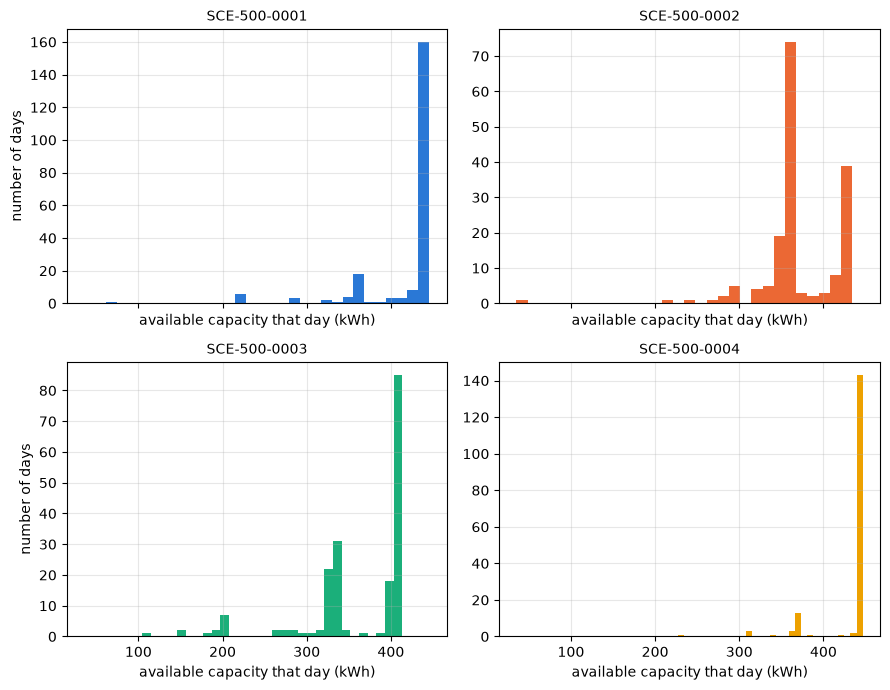

In [3]:
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True)
for ax, ep, color in zip(axes.flat, endpoints, palette):
    s = daily_capacity.loc[ep]
    ax.hist(s, bins=30, color=color)
    ax.set_title(ep, fontsize=10)
    ax.set_xlabel("available capacity that day (kWh)")
axes[0, 0].set_ylabel("number of days")
axes[1, 0].set_ylabel("number of days")
plt.tight_layout()
plt.show()


### Which packs were actually contributing

Direct check on the pack outages above: per-pack daily current, not just the
nominal-energy proxy. A pack sitting near-zero current while its siblings are
active is either isolated or faulty.

A handful of single-day readings hit implausible magnitudes (600-1,270A, when the
fleet-wide 99th percentile is 14.5A) - the same telemetry corruption seen
elsewhere, not real current. Excluded before comparing packs.


In [4]:
CURRENT_SANE_MAX = 50.0  # fleet-wide 99th percentile is 14.5A; anything past this is corrupted, not real
clean_current = pack[pack["current_avg"].abs() <= CURRENT_SANE_MAX]

rows = []
for ep, g in clean_current.groupby("endpoint_id"):
    piv = g.pivot_table(index="day", columns="pack_number", values="current_avg", aggfunc="mean")
    for pn in piv.columns:
        rows.append({"endpoint_id": ep, "pack": pn, "mean_abs_current_A": piv[pn].abs().mean(),
                     "days_near_zero": int((piv[pn].abs() < 1).sum()), "days_total": int(piv[pn].notna().sum())})
pd.DataFrame(rows).round(2)


,endpoint_id,pack,mean_abs_current_A,days_near_zero,days_total
0,SCE-500-0001,1,2.04,106,213
1,SCE-500-0001,2,2.25,104,213
2,SCE-500-0001,3,2.21,107,213
3,SCE-500-0001,4,2.40,102,213
4,SCE-500-0001,5,2.11,115,213
5,SCE-500-0001,6,2.10,115,212
6,SCE-500-0002,1,3.12,81,174
7,SCE-500-0002,2,3.04,82,174
8,SCE-500-0002,3,3.10,80,172
9,SCE-500-0002,4,3.10,82,172


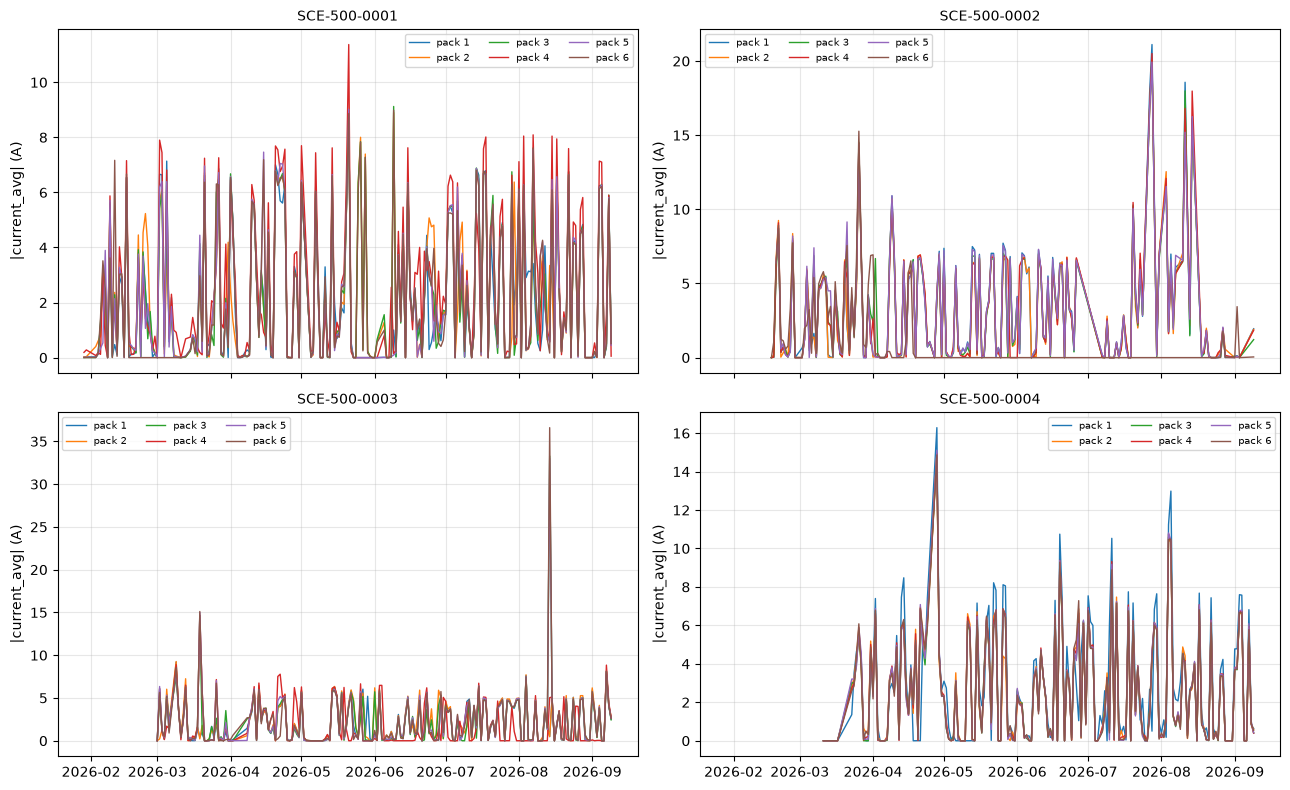

In [5]:
colors = plt.cm.tab10.colors
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, ep in zip(axes.flat, endpoints):
    g = clean_current[clean_current["endpoint_id"] == ep]
    piv = g.pivot_table(index="day", columns="pack_number", values="current_avg", aggfunc="mean")
    for pn in piv.columns:
        ax.plot(piv.index, piv[pn].abs(), label=f"pack {pn}", color=colors[pn - 1], linewidth=1)
    ax.set_title(ep, fontsize=10)
    ax.legend(fontsize=7, ncol=3)
    ax.set_ylabel("|current_avg| (A)")
plt.tight_layout()
plt.show()


SCE-500-0002 pack 6 stands out clearly: ~1A mean vs 3.1-3.3A for its 5 siblings,
idle (near-zero current) on more than 70% of days - a chronic, not brief, issue.
Every other pack across all 4 units tracks its siblings closely, so the pack3/4
dips on SCE-500-0003 and the pack4 outage on SCE-500-0001 read as real but
short-lived events, not sustained underperformance.


#### At 1-min resolution instead of daily

Daily averaging above hides *when* and *how* pack 6 was out - a day that's mostly
idle with one brief active burst looks the same as a day that's genuinely half
idle. Pulling `pack_metrics` at 1-min resolution (5.6M rows for the fleet) instead
of the daily rollup settles that.


In [6]:
p2 = pack_1min[pack_1min["endpoint_id"] == "SCE-500-0002"]
p6 = p2[p2["pack_number"] == 6].set_index("ts_min")["current_avg"].abs().dropna()
active = p6 > 1
groups = (active != active.shift()).cumsum()
runs = (
    pd.DataFrame({"active": active, "grp": groups}).reset_index()
    .groupby("grp").agg(start=("ts_min", "min"), end=("ts_min", "max"), active=("active", "first"), n=("ts_min", "size"))
)
idle_runs = runs[~runs["active"]].sort_values("n", ascending=False)
longest = idle_runs.iloc[0]
print(f"total on/off transitions: {(active.diff() != 0).sum()} over {(p6.index.max()-p6.index.min()).days} days")
print(f"longest continuous idle run: {longest['start'].date()} to {longest['end'].date()} "
      f"({longest['n']/1440:.0f} days)")


total on/off transitions: 1067 over 204 days
longest continuous idle run: 2026-04-18 to 2026-08-27 (90 days)


Not a chronic-but-noisy pack - it flickered on and off frequently early on
(Feb-mid April), then settled into one continuous idle run for essentially the
rest of the deployment. That's a materially different (and more useful) fact
than "idle on 70%+ of days" - it pins down roughly *when* the pack effectively
went out of service, not just that it was unreliable on average.


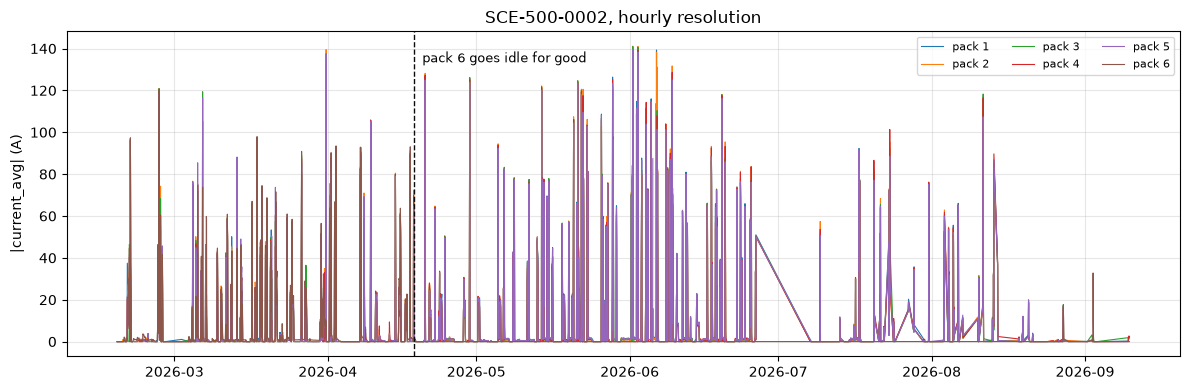

In [7]:
p2_hourly = p2.copy()
p2_hourly["hour"] = p2_hourly["ts_min"].dt.floor("h")
piv_hourly = p2_hourly.pivot_table(index="hour", columns="pack_number", values="current_avg", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 4))
for pn in piv_hourly.columns:
    ax.plot(piv_hourly.index, piv_hourly[pn].abs(), label=f"pack {pn}", color=colors[pn - 1], linewidth=0.8)
ax.axvline(longest["start"], color="#0b0b0b", linestyle="--", linewidth=1)
ax.text(longest["start"], ax.get_ylim()[1] * 0.9, "  pack 6 goes idle for good", fontsize=9)
ax.set_ylabel("|current_avg| (A)")
ax.set_title("SCE-500-0002, hourly resolution")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()


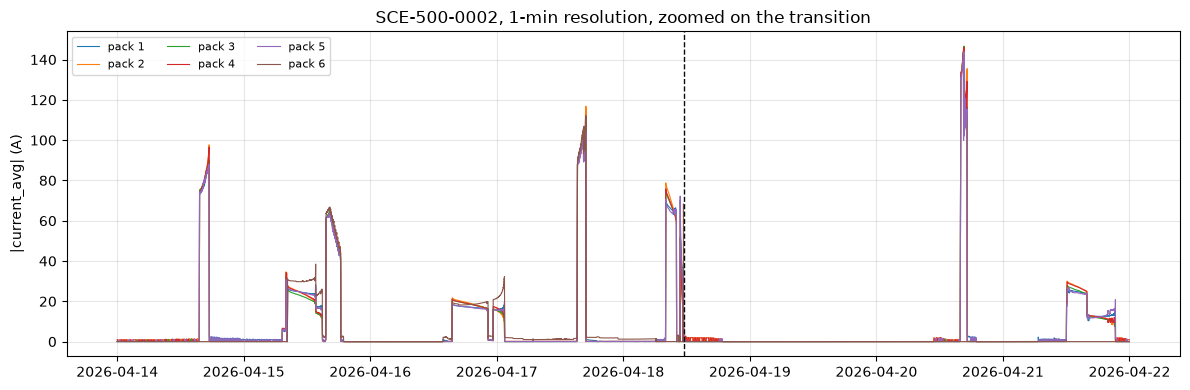

In [8]:
zoom_start, zoom_end = pd.Timestamp("2026-04-14"), pd.Timestamp("2026-04-22")
p2_zoom = p2[(p2["ts_min"] >= zoom_start) & (p2["ts_min"] < zoom_end)]
piv_zoom = p2_zoom.pivot_table(index="ts_min", columns="pack_number", values="current_avg", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 4))
for pn in piv_zoom.columns:
    ax.plot(piv_zoom.index, piv_zoom[pn].abs(), label=f"pack {pn}", color=colors[pn - 1], linewidth=0.8)
ax.axvline(longest["start"], color="#0b0b0b", linestyle="--", linewidth=1)
ax.set_ylabel("|current_avg| (A)")
ax.set_title("SCE-500-0002, 1-min resolution, zoomed on the transition")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()


## Energy throughput & duty cycle

The core finding: this isn't idle capacity. On days each unit is used, it delivers
roughly half to two-thirds of its own rated capacity, and on most active days
3-4 units run together rather than independently.

**EFC (equivalent full cycles) per day** = kWh delivered per cycle / that unit's
own capacity, summed per day - so it's directly comparable across units with
different real capacities, and consistent with kWh/day (a unit with more kWh/day
will show a higher EFC/day, by construction).


In [9]:
rows = []
all_cycles = []
for ep in endpoints:
    g = u[u["endpoint_id"] == ep].sort_values("ts_min")
    daily = daily_throughput(g)
    active_days = int((daily >= ACTIVE_DAY_MIN_KWH).sum())
    throughput_kwh = float(daily.sum())

    cycles = cycle_details(u, ep)
    cycles = cycle_energy(u, ep, cycles)
    cycles["start_day"] = pd.to_datetime(cycles["start"]).dt.floor("D")
    cap_at_start = cycles["start_day"].map(capacity_by_day[ep])
    cycles["efc"] = cycles["kwh_out"] / cap_at_start
    cycles["endpoint_id"] = ep
    all_cycles.append(cycles)

    rows.append({
        "endpoint_id": ep, "active_days": active_days,
        "throughput_kwh": round(throughput_kwh, 1),
        "kwh_per_active_day": round(throughput_kwh / active_days, 1),
        "n_cycles": len(cycles), "capacity_kwh": round(float(capacity[ep]), 0),
    })

per_unit = pd.DataFrame(rows)
all_cycles = pd.concat(all_cycles, ignore_index=True)
avg_efc = all_cycles.groupby(["endpoint_id", "start_day"])["efc"].sum().groupby("endpoint_id").mean()
per_unit["avg_efc_per_day"] = per_unit["endpoint_id"].map(avg_efc).round(2)
per_unit


,endpoint_id,active_days,throughput_kwh,kwh_per_active_day,n_cycles,capacity_kwh,avg_efc_per_day
0,SCE-500-0001,142,30202.9,212.7,154,418.0,0.65
1,SCE-500-0002,116,19845.3,171.1,138,369.0,0.65
2,SCE-500-0003,128,21307.9,166.5,139,362.0,0.61
3,SCE-500-0004,122,26634.0,218.3,104,433.0,0.70


In [10]:
total_throughput = per_unit["throughput_kwh"].sum()
total_active_days = per_unit["active_days"].sum()
print(f"Fleet total throughput:        {total_throughput:,.0f} kWh")
print(f"Fleet total active days:       {total_active_days}")
print(f"Avg throughput/unit/active day: {total_throughput/total_active_days:,.1f} kWh")
print(f"Avg EFC/unit/day range:         {avg_efc.min():.2f} - {avg_efc.max():.2f}")


Fleet total throughput:        97,990 kWh
Fleet total active days:       508
Avg throughput/unit/active day: 192.9 kWh
Avg EFC/unit/day range:         0.61 - 0.70


### Two ways to compute EFC/day - clearly labelled, both kept

**Cycle-based** (above): sum each cycle's `kwh_out / capacity`, attributed to the
day the cycle *started*, then averaged over days a cycle started.

**Simple** (below): that day's total throughput (all `ac_out_pwr`, regardless of
cycle boundaries) divided by that day's capacity, averaged over every active day.
No cycle detection at all.

These differ by design, not error: cycle-based concentrates a cycle's whole
energy onto its single start day and only averages over days a cycle *started*
(fewer days) - simple spreads the same energy across every day it actually
flowed and averages over every active day (more days). Same numerator, smaller
vs larger denominator - cycle-based reads ~20-30% higher as a direct result of
that, not because it's measuring more energy.


In [11]:
rows = []
for ep in endpoints:
    g = u[u["endpoint_id"] == ep].sort_values("ts_min")
    daily_kwh = daily_throughput(g)
    daily_kwh.index = pd.to_datetime(daily_kwh.index)
    active_daily_kwh = daily_kwh[daily_kwh >= ACTIVE_DAY_MIN_KWH]
    cap_on_day = active_daily_kwh.index.map(capacity_by_day[ep])
    efc_simple = active_daily_kwh.values / cap_on_day

    cycle_start_days = pd.to_datetime(cycle_details(u, ep)["start"]).dt.floor("D").nunique()
    rows.append({
        "endpoint_id": ep,
        "active_days": len(active_daily_kwh),
        "cycle_start_days": cycle_start_days,
        "avg_efc_per_day_simple": round(pd.Series(efc_simple).mean(), 3),
        "avg_efc_per_day_cyclebased": round(avg_efc[ep], 3),
    })
efc_comparison = pd.DataFrame(rows)
efc_comparison["diff_pct"] = round(
    100 * (efc_comparison["avg_efc_per_day_simple"] - efc_comparison["avg_efc_per_day_cyclebased"])
    / efc_comparison["avg_efc_per_day_cyclebased"], 1
)
efc_comparison


,endpoint_id,active_days,cycle_start_days,avg_efc_per_day_simple,avg_efc_per_day_cyclebased,diff_pct
0,SCE-500-0001,142,112,0.509,0.648,-21.5
1,SCE-500-0002,116,84,0.473,0.654,-27.7
2,SCE-500-0003,128,98,0.463,0.610,-24.1
3,SCE-500-0004,122,88,0.506,0.697,-27.4


### Distribution of EFC/day, per unit

The average hides the shape. These are right-skewed with a real tail - a typical
day is well under one full cycle, but some days run much deeper (or, for
SCE-500-0002, one clear outlier day above 5 - likely a day the reduced,
pack-6-out capacity was cycled unusually hard).


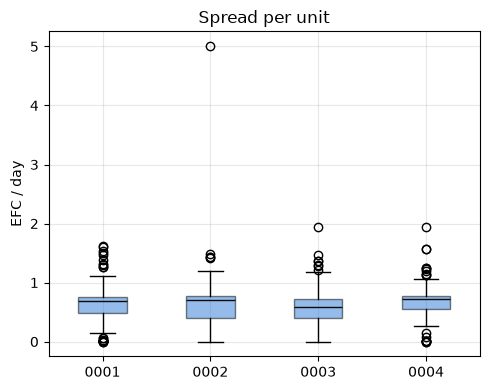

In [12]:
daily_efc_by_unit = {ep: all_cycles[all_cycles["endpoint_id"] == ep].groupby("start_day")["efc"].sum() for ep in endpoints}

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([daily_efc_by_unit[ep].values for ep in endpoints], tick_labels=[ep.replace("SCE-500-", "") for ep in endpoints],
           patch_artist=True, boxprops=dict(facecolor="#2a78d6", alpha=0.5), medianprops=dict(color="#0b0b0b"))
ax.set_ylabel("EFC / day")
ax.set_title("Spread per unit")
plt.tight_layout()
plt.show()


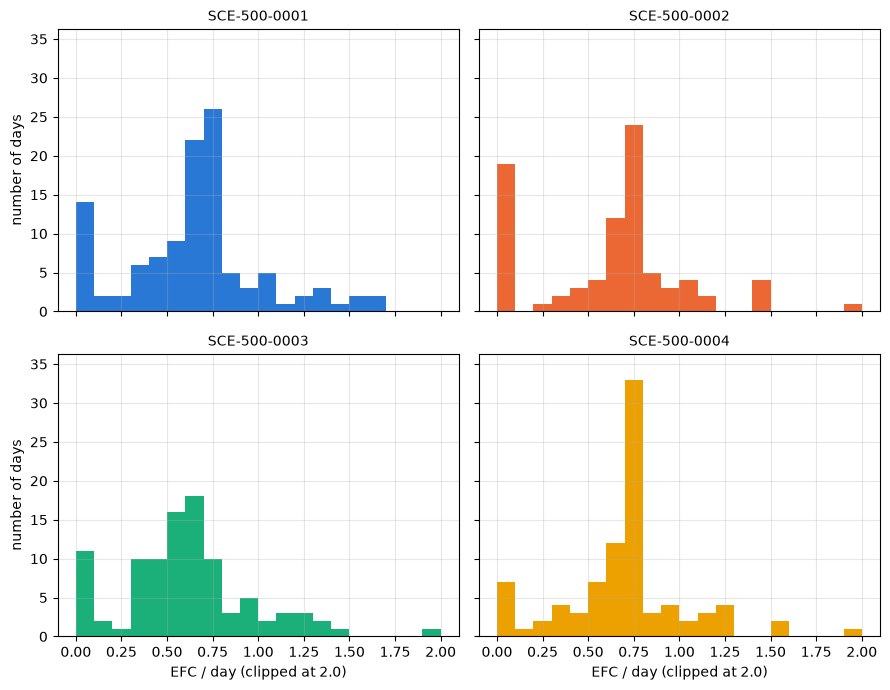

SCE-500-0001: median=0.69, IQR=[0.49, 0.75], p90=1.06, max=1.62
SCE-500-0002: median=0.71, IQR=[0.39, 0.78], p90=1.04, max=5.01
SCE-500-0003: median=0.59, IQR=[0.40, 0.72], p90=1.09, max=1.93
SCE-500-0004: median=0.73, IQR=[0.56, 0.78], p90=1.12, max=1.95


In [13]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
bins = np.linspace(0, 2.0, 21)
xmax_count = max(np.histogram(daily_efc_by_unit[ep].clip(upper=2.0), bins=bins)[0].max() for ep in endpoints)

fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for ax, ep, color in zip(axes.flat, endpoints, colors):
    ax.hist(daily_efc_by_unit[ep].clip(upper=2.0), bins=bins, color=color)
    ax.set_title(ep, fontsize=10)
    ax.set_ylim(0, xmax_count * 1.1)
for ax in axes[1]:
    ax.set_xlabel("EFC / day (clipped at 2.0)")
for ax in axes[:, 0]:
    ax.set_ylabel("number of days")
plt.tight_layout()
plt.show()

for ep in endpoints:
    s = daily_efc_by_unit[ep]
    print(f"{ep}: median={s.median():.2f}, IQR=[{s.quantile(.25):.2f}, {s.quantile(.75):.2f}], "
          f"p90={s.quantile(.9):.2f}, max={s.max():.2f}")


Since units went live at different dates (below), each unit's all-history average
throughput/active-day could in principle blend a quieter early period with a
busier later one if the site's overall demand ramped up as more units came online.
Checking that per unit, month by month, before trusting the all-history average:


In [14]:
monthly_rows = []
for ep in endpoints:
    daily = daily_throughput(u[u["endpoint_id"] == ep].sort_values("ts_min"))
    active = daily[daily >= ACTIVE_DAY_MIN_KWH]
    active.index = pd.to_datetime(active.index)
    monthly = active.groupby(active.index.to_period("M")).mean()
    for month, val in monthly.items():
        monthly_rows.append({"endpoint_id": ep, "month": str(month), "kwh_per_active_day": round(val, 1)})
monthly_df = pd.DataFrame(monthly_rows).pivot(index="month", columns="endpoint_id", values="kwh_per_active_day")
display(monthly_df)
print("No ramp-up trend per unit - values bounce around without climbing as the fleet grew, "
      "so the all-history average is representative rather than blending distinct regimes.")


endpoint_id,SCE-500-0001,SCE-500-0002,SCE-500-0003,SCE-500-0004
month,,,,
2026-02,226.4,137.3,NaN,NaN
2026-03,170.3,190.3,139.2,161.3
2026-04,175.3,176.3,151.7,223.8
2026-05,179.5,211.8,172.7,178.5
2026-06,187.3,198.7,168.4,282.2
2026-07,289.3,98.0,138.1,197.7
2026-08,226.1,113.6,231.7,190.1
2026-09,270.4,3.5,193.7,337.0


No ramp-up trend per unit - values bounce around without climbing as the fleet grew, so the all-history average is representative rather than blending distinct regimes.


### How many units run together

**Units were not all deployed at once** - SCE-500-0001 went live 29 Jan, -0002 on
17 Feb, -0003 on 1 Mar, -0004 on 11 Mar. Naively counting "units active that day"
over the whole history is confounded by this: early months could only ever show
1-2 active because units 3/4 didn't exist yet, which would inflate the apparent
climb toward "3-4 units together" for reasons that have nothing to do with how the
customer actually uses them.

So this checks the overlap finding two ways: over the whole history, and restricted
to *only* the period after all 4 units were already deployed (11 Mar onward) - if
the finding only holds in the first version, it's a rollout artifact, not real
behaviour.


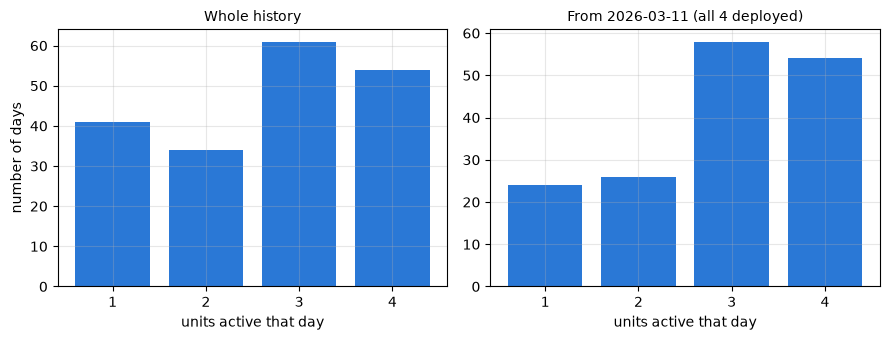

days with 3+ active, whole history:        61% (of 190 days)
days with 3+ active, post all-4-deployed:   69% (of 162 days)
Post-rollout is HIGHER, not lower - the whole-history figure is actually pulled DOWN by
the early rollout months (when only 1-2 units existed, capping the possible count). If
the finding were a rollout artifact it would go the other way. Genuine usage pattern.


In [15]:
active_by_day = {}
for ep in endpoints:
    daily = daily_throughput(u[u["endpoint_id"] == ep].sort_values("ts_min"))
    active_by_day[ep] = set(daily[daily >= ACTIVE_DAY_MIN_KWH].index)
all_days = sorted(set().union(*active_by_day.values()))
overlap_counts = pd.Series([sum(d in active_by_day[ep] for ep in active_by_day) for d in all_days]).value_counts().sort_index()

all4_start = u.groupby("endpoint_id")["ts_min"].min().max().floor("D")  # when the last unit came online
post_days = [d for d in all_days if d >= all4_start]
post_overlap_counts = pd.Series([sum(d in active_by_day[ep] for ep in active_by_day) for d in post_days]).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, counts, title in zip(axes, [overlap_counts, post_overlap_counts], ["Whole history", f"From {all4_start.date()} (all 4 deployed)"]):
    ax.bar(counts.reindex(range(1,5), fill_value=0).index.astype(str), counts.reindex(range(1,5), fill_value=0).values, color="#2a78d6")
    ax.set_xlabel("units active that day")
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("number of days")
plt.tight_layout()
plt.show()

pct_whole = 100*overlap_counts.reindex([3,4], fill_value=0).sum()/overlap_counts.sum()
pct_post = 100*post_overlap_counts.reindex([3,4], fill_value=0).sum()/post_overlap_counts.sum()
print(f"days with 3+ active, whole history:        {pct_whole:.0f}% (of {overlap_counts.sum()} days)")
print(f"days with 3+ active, post all-4-deployed:   {pct_post:.0f}% (of {post_overlap_counts.sum()} days)")
print("Post-rollout is HIGHER, not lower - the whole-history figure is actually pulled DOWN by")
print("the early rollout months (when only 1-2 units existed, capping the possible count). If")
print("the finding were a rollout artifact it would go the other way. Genuine usage pattern.")


### Did they need each unit added, and is there room for more?

The units weren't all bought at once - they were added one at a time (1, then 2,
then 3, then 4). That's a natural test: if adding a unit just **split the same
existing demand thinner**, fleet throughput *per live unit* should decline as more
units come online. If each addition instead found **genuinely new demand**,
throughput-per-live-unit should hold roughly steady (or grow) rather than fall.


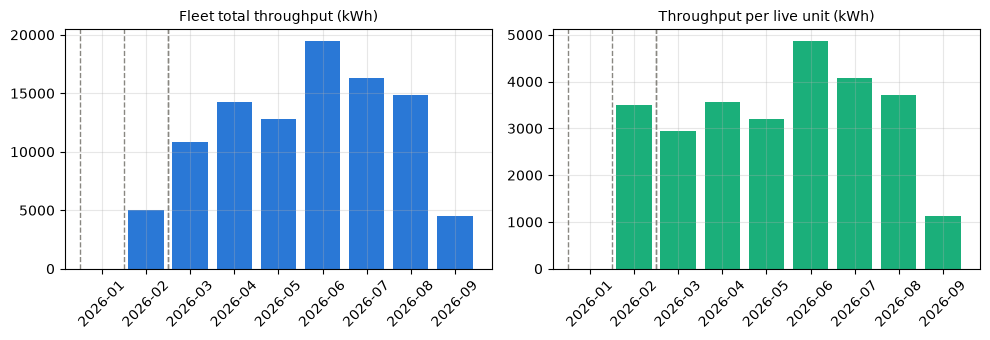

go-live:  SCE-500-0001=2026-01-29, SCE-500-0002=2026-02-17, SCE-500-0003=2026-03-01, SCE-500-0004=2026-03-11

avg units live per month:
2026-01    1.00
2026-02    1.43
2026-03    3.68
2026-04    4.00
2026-05    4.00
2026-06    4.00
2026-07    4.00
2026-08    4.00
2026-09    4.00
Freq: M

throughput per live unit per month (kWh) - flat/noisy, NOT declining as units were added:
month
2026-01       0.0
2026-02    3494.0
2026-03    2948.0
2026-04    3560.0
2026-05    3195.0
2026-06    4873.0
2026-07    4069.0
2026-08    3723.0
2026-09    1119.0
Freq: M


In [16]:
go_live = u.groupby("endpoint_id")["ts_min"].min().dt.floor("D")

daily_all = []
for ep in endpoints:
    d = daily_throughput(u[u["endpoint_id"] == ep].sort_values("ts_min")).rename("kwh").reset_index().rename(columns={"ts_min": "day"})
    daily_all.append(d)
daily_all = pd.concat(daily_all, ignore_index=True)
daily_all["month"] = pd.to_datetime(daily_all["day"]).dt.to_period("M")
fleet_monthly = daily_all.groupby("month")["kwh"].sum()

all_days_range = pd.date_range(u["ts_min"].min().floor("D"), u["ts_min"].max().floor("D"), freq="D")
n_live = pd.Series([sum(go_live[ep] <= d for ep in go_live.index) for d in all_days_range], index=all_days_range)
n_live_monthly = n_live.groupby(n_live.index.to_period("M")).mean()
per_live_unit_monthly = fleet_monthly / n_live_monthly

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
months_str = [str(m) for m in fleet_monthly.index]
axes[0].bar(months_str, fleet_monthly.values, color="#2a78d6")
axes[0].set_title("Fleet total throughput (kWh)", fontsize=10)
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(months_str, per_live_unit_monthly.values, color="#1baf7a")
axes[1].set_title("Throughput per live unit (kWh)", fontsize=10)
axes[1].tick_params(axis="x", rotation=45)
for ax in axes:
    for i, ep in enumerate(endpoints):
        m = go_live[ep].to_period("M")
        if str(m) in months_str:
            ax.axvline(months_str.index(str(m)) - 0.5, color="#898781", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

print("go-live: ", ", ".join(f"{ep}={go_live[ep].date()}" for ep in endpoints))
print("\navg units live per month:")
print(n_live_monthly.round(2).to_string())
print("\nthroughput per live unit per month (kWh) - flat/noisy, NOT declining as units were added:")
print(per_live_unit_monthly.round(0).to_string())


No dilution: throughput-per-live-unit stays in the same ~3,000-4,900 kWh/month band
whether 1 unit was live or all 4 were. Each unit added found its own genuine use
rather than splitting a fixed pool of demand - real evidence the units were needed.

What this *doesn't* show: total fleet throughput has been roughly flat (noisy, no
clear climb) since all 4 went live in March - so there's no direct signal here of
demand still growing *beyond* the current fleet. Combined with the EFC/day figures
above (0.56-0.69, comfortably under a full cycle/day) and the earlier finding that
power headroom is ample, the honest read is: **the fleet is being used, not
under-used** - each unit added has justified itself - but this data alone doesn't
prove unmet demand for a 5th. That would need either a period where the 4-unit
fleet visibly can't keep up, or direct evidence (declined jobs, turned-away
vehicles) that doesn't exist in the data available here.


### Usage rhythm

Clear weekday pattern - essentially no weekend use. Consistent with a construction/
industrial site cadence rather than continuous operation.


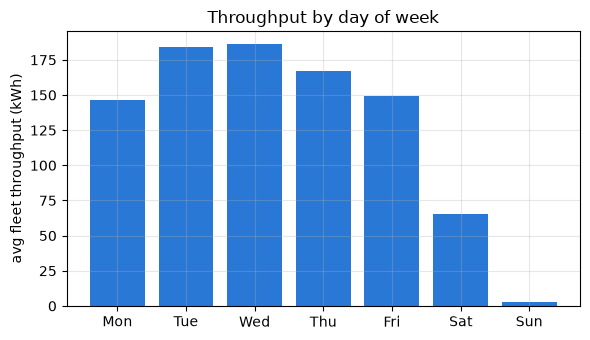

dow
Monday       146.4
Tuesday      183.9
Wednesday    186.0
Thursday     167.3
Friday       149.5
Saturday      65.7
Sunday         2.8
Name: kwh, dtype: float64

In [17]:
daily_all = []
for ep in endpoints:
    d = daily_throughput(u[u["endpoint_id"] == ep].sort_values("ts_min")).rename("kwh").reset_index().rename(columns={"ts_min": "day"})
    daily_all.append(d)
daily_all = pd.concat(daily_all, ignore_index=True)
daily_all["dow"] = pd.to_datetime(daily_all["day"]).dt.day_name()
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_kwh = daily_all.groupby("dow")["kwh"].mean().reindex(dow_order)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([d[:3] for d in dow_order], weekday_kwh.values, color="#2a78d6")
ax.set_ylabel("avg fleet throughput (kWh)")
ax.set_title("Throughput by day of week")
plt.tight_layout()
plt.show()
weekday_kwh.round(1)


### Daily intensity, full period

Fleet-wide EFC per day (capacity-normalized, summed across all 4 units) across
the whole deployment history. A day with all 4 units each doing one full cycle
would read ~4.0.


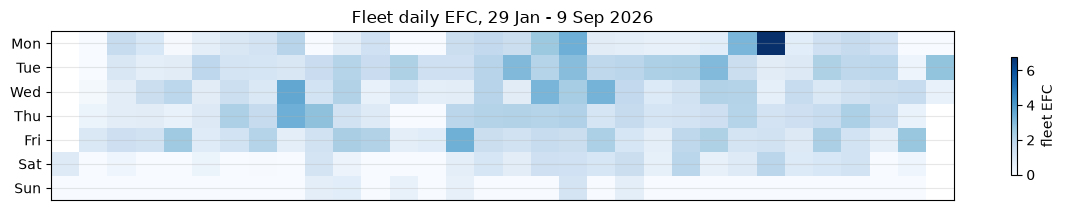

daily mean: 1.16, median: 1.09, max: 6.80


In [18]:
fleet_daily_efc = all_cycles.groupby("start_day")["efc"].sum()
full_range = pd.date_range(fleet_daily_efc.index.min(), fleet_daily_efc.index.max(), freq="D")
fleet_daily_efc = fleet_daily_efc.reindex(full_range, fill_value=0)

# calendar-style grid: weeks x weekday
start = fleet_daily_efc.index.min()
start_weekday = start.weekday()
padded = pd.concat([pd.Series([np.nan] * start_weekday), fleet_daily_efc.reset_index(drop=True)])
n_weeks = int(np.ceil(len(padded) / 7))
padded = pd.concat([padded, pd.Series([np.nan] * (n_weeks * 7 - len(padded)))]).values.reshape(n_weeks, 7).T

fig, ax = plt.subplots(figsize=(12, 2.2))
im = ax.imshow(padded, aspect="auto", cmap="Blues", vmin=0)
ax.set_yticks(range(7))
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks([])
ax.set_title("Fleet daily EFC, 29 Jan - 9 Sep 2026")
fig.colorbar(im, ax=ax, label="fleet EFC", shrink=0.7)
plt.tight_layout()
plt.show()
print(f"daily mean: {fleet_daily_efc.mean():.2f}, median: {fleet_daily_efc.median():.2f}, max: {fleet_daily_efc.max():.2f}")


## Round-trip efficiency

Per cycle: kWh out / kWh in, restricted to cycles with a meaningful amount of both
(a cycle that re-triggers almost immediately only captures a recharge's topping-off
tail with barely any discharge, which isn't a meaningful reading).


In [19]:
rows = []
for ep in endpoints:
    cycles = cycle_details(u, ep)
    cycles = cycle_energy(u, ep, cycles)
    valid = cycles[(cycles["kwh_in"] > 5) & (cycles["kwh_out"] > 5)]
    eff = valid["kwh_out"] / valid["kwh_in"]
    rows.append({"endpoint_id": ep, "n_cycles": len(valid), "mean_eff": eff.mean(),
                 "median_eff": eff.median(), "p10": eff.quantile(.1), "p90": eff.quantile(.9)})
pd.DataFrame(rows).round(3)


,endpoint_id,n_cycles,mean_eff,median_eff,p10,p90
0,SCE-500-0001,104,0.806,0.789,0.659,0.943
1,SCE-500-0002,74,0.779,0.806,0.631,0.900
2,SCE-500-0003,93,0.810,0.788,0.632,0.922
3,SCE-500-0004,84,0.790,0.796,0.667,0.921


## Capacity trend

BMS-reported nominal capacity, first vs last full month of data (months with
fewer than 15 days of readings excluded - a partial onboarding month isn't a fair
capacity reading). Same pack-outage filter as above, so a known pack dropout
doesn't read as a capacity dip. No fade signal across ~7 months; if anything
capacity estimates drift up slightly, likely BMS recalibration as it accumulates
cycles rather than genuine degradation.


In [20]:
rows = []
for ep in endpoints:
    s = daily_capacity.loc[ep].sort_index()
    counts = s.resample("ME").count()
    monthly = s.resample("ME").mean()
    monthly = monthly[counts >= 15]
    rows.append({"endpoint_id": ep, "first_full_month_kwh": round(monthly.iloc[0], 0),
                 "last_full_month_kwh": round(monthly.iloc[-1], 0),
                 "change_pct": round(100 * (monthly.iloc[-1] - monthly.iloc[0]) / monthly.iloc[0], 1)})
pd.DataFrame(rows)


,endpoint_id,first_full_month_kwh,last_full_month_kwh,change_pct
0,SCE-500-0001,383.0,441.0,15.2
1,SCE-500-0002,362.0,358.0,-1.1
2,SCE-500-0003,350.0,364.0,4.0
3,SCE-500-0004,436.0,432.0,-1.0


## Location

Units are mobile, not fixed - redeployed roughly every 1-3 weeks across a small
geographic cluster (Essex/London area), the same small fleet moved between jobs
rather than one unit per site.


In [21]:
for row in location_summary(loc):
    print(f"{row['endpoint_id']}: {row['n_distinct_locations']} distinct locations")


SCE-500-0001: 6 distinct locations
SCE-500-0002: 4 distinct locations
SCE-500-0003: 4 distinct locations
SCE-500-0004: 5 distinct locations


## Time of use

When during the day the fleet actually delivers and draws energy - not just
which days (Usage rhythm, above), but which hours. Weekdays only (weekends
run near-zero, as already shown); hour is local wall-clock time as recorded
in `ts_min` - the source data carries no timezone field to check it against.


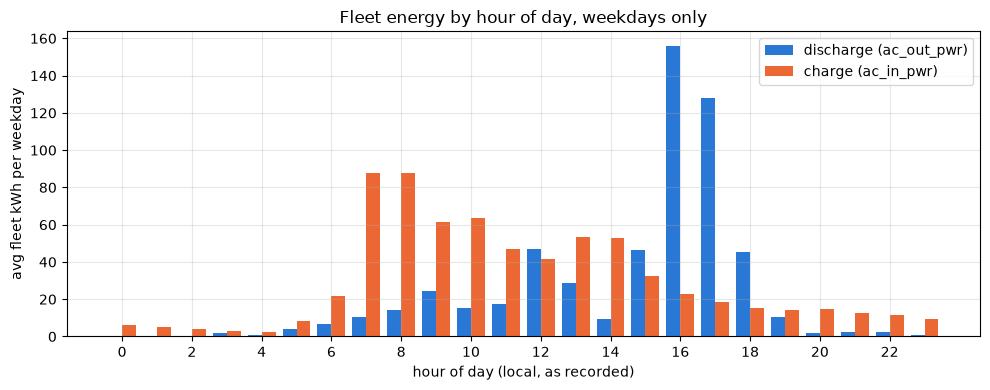

Peak discharge hour: 16:00 (156 kWh/weekday avg, fleet-wide)
Peak charge hour:    07:00 (88 kWh/weekday avg, fleet-wide)
Share of discharge in 07:00-19:59 window: 96%
Share of charge in 07:00-19:59 window:    86%


In [22]:
tou = u.copy()
tou["dow"] = tou["ts_min"].dt.day_name()
tou["hour"] = tou["ts_min"].dt.hour
weekday_tou = tou[~tou["dow"].isin(["Saturday", "Sunday"])]
n_weekdays = weekday_tou["ts_min"].dt.floor("D").nunique()

hourly_out = weekday_tou.groupby("hour")["ac_out_pwr"].apply(lambda s: s.clip(lower=0).sum() / 60.0) / n_weekdays
hourly_in = weekday_tou.groupby("hour")["ac_in_pwr"].apply(lambda s: s.clip(lower=0).sum() / 60.0) / n_weekdays

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly_out.index - 0.2, hourly_out.values, width=0.4, label="discharge (ac_out_pwr)", color="#2a78d6")
ax.bar(hourly_in.index + 0.2, hourly_in.values, width=0.4, label="charge (ac_in_pwr)", color="#eb6834")
ax.set_xlabel("hour of day (local, as recorded)")
ax.set_ylabel("avg fleet kWh per weekday")
ax.set_title("Fleet energy by hour of day, weekdays only")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

day_window = range(7, 20)  # 07:00-19:59
day_frac_out = hourly_out.reindex(day_window).sum() / hourly_out.sum()
day_frac_in = hourly_in.reindex(day_window).sum() / hourly_in.sum()
print(f"Peak discharge hour: {hourly_out.idxmax():02d}:00 ({hourly_out.max():.0f} kWh/weekday avg, fleet-wide)")
print(f"Peak charge hour:    {hourly_in.idxmax():02d}:00 ({hourly_in.max():.0f} kWh/weekday avg, fleet-wide)")
print(f"Share of discharge in 07:00-19:59 window: {100*day_frac_out:.0f}%")
print(f"Share of charge in 07:00-19:59 window:    {100*day_frac_in:.0f}%")


Sharply daytime: 96% of discharge and 85% of charging happen between 07:00 and
20:00. Discharge peaks hard at 16:00, while charging peaks earlier, around
08:00 - a working-day pattern (charge in the morning, discharge through the
afternoon), not one shaped by an overnight tariff window.

The ~15% of charging outside 07:00-19:59 (vs only 4% of discharge) is the one
asymmetry - some recharging spills into the evening/night, consistent with
units coming back partially depleted after an afternoon of heavy discharge
and finishing the top-up overnight rather than within the working day.


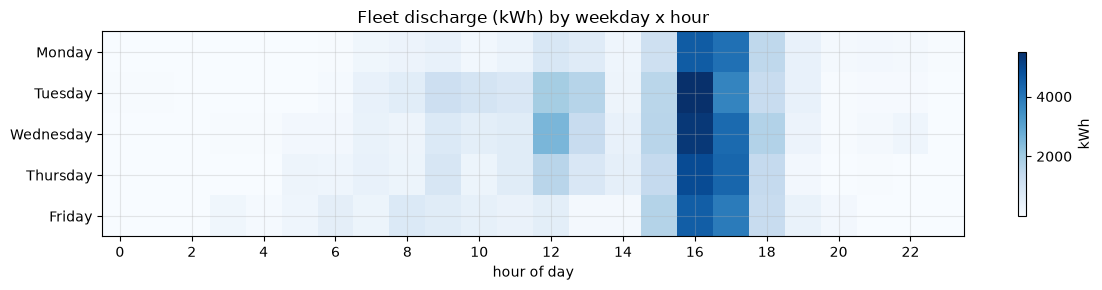

Peak discharge hour, per weekday:
dow
Monday       16
Tuesday      16
Wednesday    16
Thursday     16
Friday       16


In [23]:
piv_tou = weekday_tou.groupby(["dow", "hour"])["ac_out_pwr"].apply(lambda s: s.clip(lower=0).sum() / 60.0).unstack("hour")
piv_tou = piv_tou.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])

fig, ax = plt.subplots(figsize=(12, 3))
im = ax.imshow(piv_tou.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(piv_tou.index)))
ax.set_yticklabels(piv_tou.index)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel("hour of day")
ax.set_title("Fleet discharge (kWh) by weekday x hour")
fig.colorbar(im, ax=ax, label="kWh", shrink=0.8)
plt.tight_layout()
plt.show()

per_weekday_peak = piv_tou.idxmax(axis=1)
print("Peak discharge hour, per weekday:")
print(per_weekday_peak.to_string())


Same 16:00 peak on every single weekday (Monday-Friday all individually peak
at that hour) - the afternoon peak isn't an artefact of averaging across
different days with different peak times, it's the same pattern repeating.


## Charge time

How long a unit spends actually charging, and how that relates to how much
SoC it actually gained - duration alone doesn't say much without it, since a
brief float/maintenance top-up and a genuine near-empty-to-full charge both
just look like "a session" otherwise.

A "charging session" is detected the same way as the AC-output "sessions"
earlier in the notebook (power above 1 kW, gaps up to 5 minutes bridged) -
applied to `ac_in_pwr` instead of discharge. Each session is then tagged with
`soc_avg` at its start and end (nearest 1-min sample) to get the SoC actually
gained, not just elapsed time.


In [24]:
def detect_power_sessions(g, col):
    g = g.dropna(subset=[col]).set_index("ts_min").sort_index()
    active = g[col].abs() > LOAD_ON_THRESHOLD_KW
    active = active.reindex(pd.date_range(g.index.min(), g.index.max(), freq="1min"), fill_value=False)
    run_id = (active != active.shift()).cumsum()
    run_len = active.groupby(run_id).transform("size")
    bridged = active | (~active & (run_len <= SESSION_GAP_MIN))
    session_id = (bridged != bridged.shift(fill_value=False)).cumsum()
    sessions = (
        pd.DataFrame({"active": bridged, "session_id": session_id}).reset_index(names="ts")
        .groupby("session_id").agg(start=("ts", "min"), end=("ts", "max"), active=("active", "first"))
    )
    sessions = sessions[sessions["active"]].copy()
    sessions["duration_h"] = (sessions["end"] - sessions["start"]) / np.timedelta64(1, "h") + (1 / 60)
    return sessions.reset_index(drop=True)

CHARGE_SOC_MIN = 5.0  # a session that gained less SoC than this is float/maintenance
                       # charging or noise, not a meaningful charge - excluded below

all_charge_sessions = []
for ep in endpoints:
    g = u[u["endpoint_id"] == ep].sort_values("ts_min").reset_index(drop=True)
    sess = detect_power_sessions(g, "ac_in_pwr")
    soc_series = g.set_index("ts_min")["soc_avg"]
    sess["soc_start"] = soc_series.reindex(sess["start"], method="nearest").to_numpy()
    sess["soc_end"] = soc_series.reindex(sess["end"], method="nearest").to_numpy()
    sess["delta_soc"] = sess["soc_end"] - sess["soc_start"]
    sess["endpoint_id"] = ep
    all_charge_sessions.append(sess)
all_charge_sessions = pd.concat(all_charge_sessions, ignore_index=True)

meaningful = all_charge_sessions[all_charge_sessions["delta_soc"] >= CHARGE_SOC_MIN].copy()
meaningful["rate_pct_per_h"] = meaningful["delta_soc"] / meaningful["duration_h"]

n_excluded = len(all_charge_sessions) - len(meaningful)
n_negative = (all_charge_sessions["delta_soc"] < 0).sum()
print(f"{len(all_charge_sessions)} charging sessions detected; {n_excluded} excluded as "
      f"< {CHARGE_SOC_MIN:.0f}% SoC gained (of which {n_negative} actually show a net SoC "
      f"*drop* - a session where the unit charged and discharged in the same window, or a "
      f"brief power blip either side of it).")

rows = []
for ep, g in meaningful.groupby("endpoint_id"):
    rows.append({
        "endpoint_id": ep, "n_meaningful_sessions": len(g),
        "median_duration_h": round(g["duration_h"].median(), 2),
        "median_delta_soc": round(g["delta_soc"].median(), 1),
        "median_rate_pct_per_h": round(g["rate_pct_per_h"].median(), 1),
    })
pd.DataFrame(rows)


809 charging sessions detected; 233 excluded as < 5% SoC gained (of which 28 actually show a net SoC *drop* - a session where the unit charged and discharged in the same window, or a brief power blip either side of it).


,endpoint_id,n_meaningful_sessions,median_duration_h,median_delta_soc,median_rate_pct_per_h
0,SCE-500-0001,161,2.73,52.9,17.9
1,SCE-500-0002,131,1.92,41.5,19.2
2,SCE-500-0003,153,1.95,40.0,19.2
3,SCE-500-0004,131,2.17,55.2,24.5


Duration scales with how much SoC is actually being added, not a fixed
"plug-in time" - a session gaining 10% and one gaining 80% are different
events, which is exactly why raw session duration alone (the earlier cut of
this analysis) wasn't the right number to lead with. Normalising each
session's own rate (`delta_soc / duration_h`) up to a full 0-100% swing gives
one comparable number per unit: **equivalent time to a full charge**.


In [25]:
meaningful["equiv_full_charge_h"] = 100.0 / meaningful["rate_pct_per_h"]

equiv_full = meaningful.groupby("endpoint_id")["equiv_full_charge_h"].agg(
    median_h="median", mean_h="mean", n="size"
).round(2)
equiv_full


,median_h,mean_h,n
endpoint_id,,,
SCE-500-0001,5.60,7.83,161
SCE-500-0002,5.21,7.32,131
SCE-500-0003,5.20,7.84,153
SCE-500-0004,4.09,5.95,131


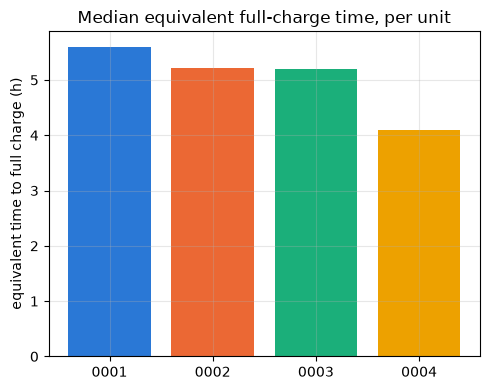

Fleet median equivalent full-charge time: 4.9h
Fleet mean:                               7.3h (pulled up by a right-skewed tail - a handful of slow, low-rate sessions)


In [26]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar([ep.replace("SCE-500-", "") for ep in endpoints], equiv_full.loc[endpoints, "median_h"], color=palette)
ax.set_ylabel("equivalent time to full charge (h)")
ax.set_title("Median equivalent full-charge time, per unit")
plt.tight_layout()
plt.show()
print(f"Fleet median equivalent full-charge time: {meaningful['equiv_full_charge_h'].median():.1f}h")
print(f"Fleet mean:                               {meaningful['equiv_full_charge_h'].mean():.1f}h "
      f"(pulled up by a right-skewed tail - a handful of slow, low-rate sessions)")


**~4-6h median equivalent time to a full charge**, per unit (fleet median
4.9h) - the mean (6-8h) reads higher only because a handful of slow, low-rate
sessions pull it up; the median is the more representative single number.
This is a normalised, not observed, figure - no session in the data actually
ran a real 0-100% charge start to finish; it's each session's own rate
projected across a full swing, which is what makes units comparable
regardless of how depleted they happened to be when a given session started.

SCE-500-0004 is the fastest (4.1h) despite having the fleet's *largest*
average capacity (441 kWh vs 397-433 kWh for the others) - not a
smaller-battery effect. It's genuinely charged harder: 32% of its
charging-minutes are above 100 kW and 20% above 150 kW, both clearly the
highest in the fleet (next is -0002 at 24%/10%), while median charging power
is similar across all four units (~46-52 kW). A real charger-power/site
difference, not a measurement artefact.


In [27]:
CHARGE_START_BINS = [0, 30, 50, 70, 85, 101]
CHARGE_START_LABELS = ["<30", "30-50", "50-70", "70-85", "85+"]

near_full = meaningful[meaningful["soc_end"] >= 80].copy()
near_full["start_band"] = pd.cut(near_full["soc_start"], bins=CHARGE_START_BINS, labels=CHARGE_START_LABELS)

time_to_full = near_full.groupby("start_band", observed=True).agg(
    n=("duration_h", "size"), median_duration_h=("duration_h", "median"), median_start_soc=("soc_start", "median"),
)
time_to_full


,n,median_duration_h,median_start_soc
start_band,,,
<30,195,2.900000,16.040000
30-50,96,2.583333,39.551963
50-70,91,1.750000,59.400000
70-85,53,1.216667,77.211333
85+,18,0.716667,87.472453


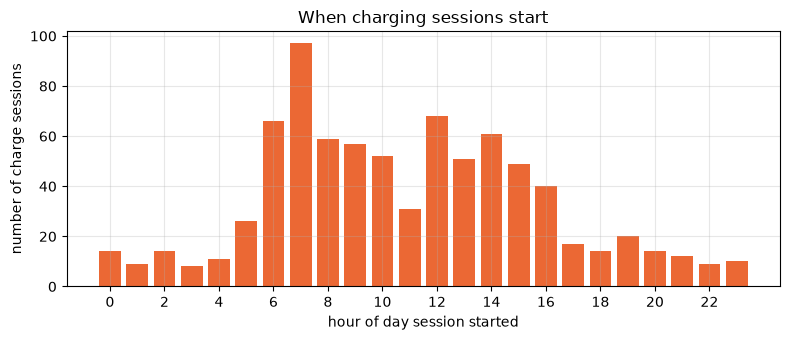

In [28]:
all_charge_sessions["start_hour"] = all_charge_sessions["start"].dt.hour
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(24), all_charge_sessions["start_hour"].value_counts().reindex(range(24), fill_value=0).values, color="#eb6834")
ax.set_xlabel("hour of day session started")
ax.set_ylabel("number of charge sessions")
ax.set_title("When charging sessions start")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()


Restricting to sessions that actually finish near-full (SoC ends >=80%) and
grouping by how depleted the unit was at the start: time-to-full scales
cleanly with starting SoC, from a median ~2.9h from below 30% down to
~0.7h from 85%+ - a straightforward "less to add, less time needed"
relationship, not a fixed charge-cycle duration. Across all meaningful
sessions the per-unit median charge rate sits around 18-25%/h (table above).

Sessions mostly start in the morning (06:00-13:00 accounts for the bulk of
session starts), consistent with the Time of use finding above - units come
back from the previous day's discharge and get topped up before the next
working day's use.


## Temperature

Cell temperature at the pack level (`celltempmax_avg` - the average of each
pack's own max-cell reading that day). A handful of readings are exactly
0.0degC - the same telemetry-defaults-to-zero pattern seen elsewhere (soc_avg,
total_kwh_in/out) - and are excluded (69 of 4,200 pack-days, 1.6%).
`celltempmin_min` has the same problem far more often (44% of pack-days read
exactly 0.0degC, spread evenly across every month including July/August in
the UK - clearly a telemetry floor, not real ambient cold), so it isn't used
here; noted under Data quality & dead ends below.


In [29]:
clean_temp = pack[pack["celltempmax_avg"] > 0].copy()
clean_temp["day"] = pd.to_datetime(clean_temp["day"])

rows = []
for ep, g in clean_temp.groupby("endpoint_id"):
    rows.append({
        "endpoint_id": ep,
        "mean_max_temp_c": round(g["celltempmax_avg"].mean(), 1),
        "p95_max_temp_c": round(g["celltempmax_avg"].quantile(.95), 1),
        "peak_ever_c": round(g["celltempmax_max"].max(), 1),
        "days_over_45c": int((g["celltempmax_avg"] > 45).sum()),
    })
pd.DataFrame(rows)


,endpoint_id,mean_max_temp_c,p95_max_temp_c,peak_ever_c,days_over_45c
0,SCE-500-0001,27.8,39.1,56.0,0
1,SCE-500-0002,26.1,41.5,57.0,16
2,SCE-500-0003,26.9,39.9,56.5,5
3,SCE-500-0004,30.0,41.5,57.0,8


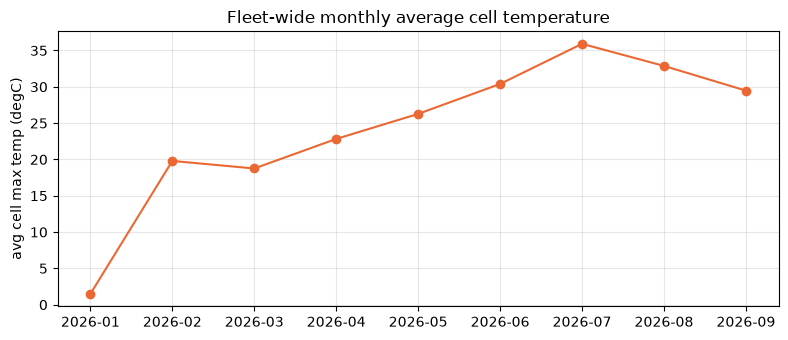

day
2026-01     1.5
2026-02    19.8
2026-03    18.8
2026-04    22.8
2026-05    26.3
2026-06    30.4
2026-07    35.9
2026-08    32.9
2026-09    29.5
Freq: M, Name: celltempmax_avg, dtype: float64

In [30]:
monthly_temp = clean_temp.groupby(clean_temp["day"].dt.to_period("M"))["celltempmax_avg"].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot([str(m) for m in monthly_temp.index], monthly_temp.values, marker="o", color="#eb6834")
ax.set_ylabel("avg cell max temp (degC)")
ax.set_title("Fleet-wide monthly average cell temperature")
plt.tight_layout()
plt.show()
monthly_temp.round(1)


### Daily, with min/max, against London ambient

Same signal at daily resolution instead of monthly, all three drawn from
`celltempmax` (the hottest-cell reading): the fleet-wide daily **avg** and
**max** come from the daily rollup used above; the daily **min** needs the
1-min data instead (the daily rollup only carries avg/max, not min) - fleet
lowest `celltempmax_avg` reading across all packs, that day. This min line
doesn't have the stuck-value filtering applied further down in this notebook
(that machinery is built later, using this same 1-min data) - a handful of
days could reflect a frozen reading rather than a genuinely-reached low, so
treat isolated dips in the min line with a little more caution than the
avg/max lines.

Overlaid: London daily mean air temperature for the same date range (Open-
Meteo historical archive, ERA5-based - `scripts/pull_weather.py`) as the
ambient baseline this dataset otherwise lacks.


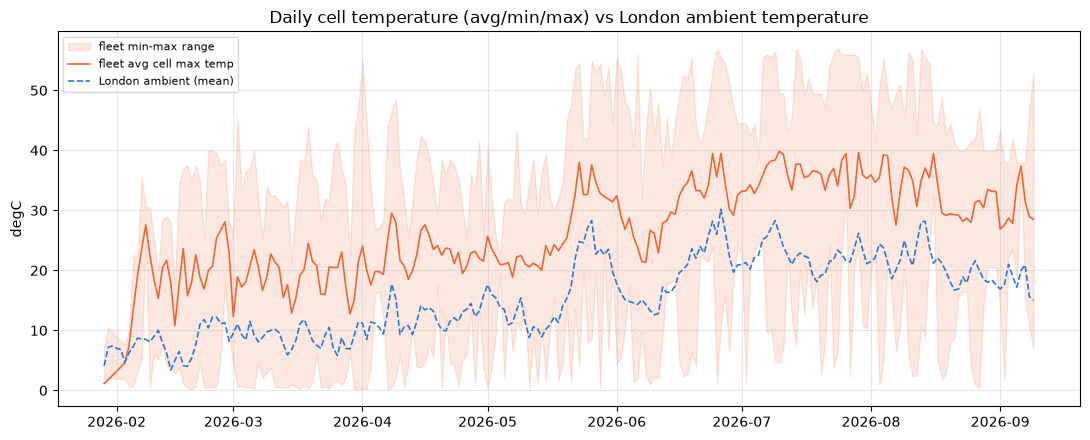

In [31]:
daily_avg = clean_temp.groupby("day")["celltempmax_avg"].mean()
daily_max = clean_temp.groupby("day")["celltempmax_max"].max()
daily_min = pack_1min.groupby(pack_1min["ts_min"].dt.floor("D"))["celltempmax_avg"].min()
daily_min.index.name = "day"

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(daily_min.index, daily_min.values, daily_max.reindex(daily_min.index).values,
                 color="#eb6834", alpha=0.15, label="fleet min-max range")
ax.plot(daily_avg.index, daily_avg.values, color="#eb6834", linewidth=1.2, label="fleet avg cell max temp")
ax.plot(weather["day"], weather["ambient_temp_mean_c"], color="#2a78d6", linewidth=1.2,
        linestyle="--", label="London ambient (mean)")
ax.set_ylabel("degC")
ax.set_title("Daily cell temperature (avg/min/max) vs London ambient temperature")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


Cell temperature tracks ambient closely in shape - both climb through spring
into a summer peak and ease into September - and runs consistently above it,
as expected (cells self-heat under load; ambient is just the floor they're
heating from). From February onward the gap sits in a fairly stable
10-13degC band, with a mild uptick in the hottest months (~13degC in July vs
~10degC in April/May) rather than a dramatic widening - load-driven heating
on top of the ambient baseline, not something growing out of proportion with
it. January is the one outlier (cell temp briefly reading *below* ambient) -
that's the deployment's first commissioning week for SCE-500-0001 with very
few readings, not a real signal.


### Deviation from ambient

The gap between the orange and blue lines above, drawn as its own series -
strips out the shared seasonal climb so whatever's left is the load-driven
part, not just "it's summer".


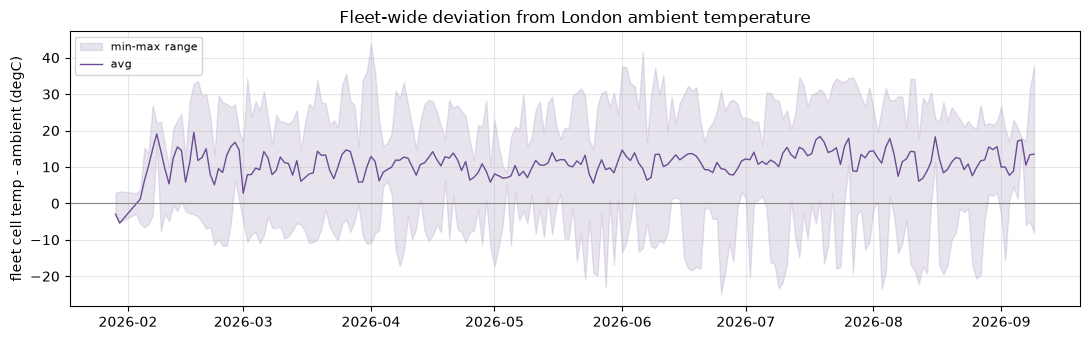

mean deviation (avg line): 11.0degC, std: 3.5degC


In [32]:
weather_by_day = weather.set_index("day")["ambient_temp_mean_c"]
fleet_dev = (daily_avg - weather_by_day).dropna()
fleet_dev_min = (daily_min - weather_by_day).dropna()
fleet_dev_max = (daily_max - weather_by_day).dropna()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.fill_between(fleet_dev.index, fleet_dev_min.reindex(fleet_dev.index).values,
                 fleet_dev_max.reindex(fleet_dev.index).values, color="#6a4c93", alpha=0.15, label="min-max range")
ax.plot(fleet_dev.index, fleet_dev.values, color="#6a4c93", linewidth=1, label="avg")
ax.axhline(0, color="#898781", linewidth=0.8)
ax.set_ylabel("fleet cell temp - ambient (degC)")
ax.set_title("Fleet-wide deviation from London ambient temperature")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"mean deviation (avg line): {fleet_dev.mean():.1f}degC, std: {fleet_dev.std():.1f}degC")


The avg line sits in a fairly steady 9-13degC band for most of the
deployment (mean ~11degC) - noisy day to day but no runaway trend up or
down. The one excursion below zero is the January commissioning-week
artifact noted above, not a real cold snap in the cells.

The band is wider than the avg line alone suggests, and the bottom of it is
routinely *below* ambient (roughly -4 to -9degC through the deployment) -
that's the fleet's single coolest pack-reading each day. Checked which pack
that actually is before reading anything into it: no single chronic culprit
(it isn't, say, the known-idle SCE-500-0002 pack 6, which only sets the daily
minimum on 13 of ~220 days) - pack 1 on various units sets it most often
(SCE-500-0003, -0001, -0002 and -0004's pack 1 between them account for over
half of all days), a mild but consistent cross-unit pattern worth a look as
a possible rack-position/airflow effect, not a single faulty pack. The top
of the band climbs from ~22degC above ambient in February to ~28-29degC in
June/July, alongside a similar widening at the bottom - both ends pull
further from ambient in the warmer months, not just the hot side.


**Is the below-ambient dip just a resolution mismatch?** The fleet min is
the single coldest reading out of ~24 packs x 1,440 minutes/day (~35,000
samples), compared above against London's *daily mean* temperature - an
extreme-of-many-samples compared against a smoothed daily average is not a
fair comparison on its own; the min should read low almost by construction,
whether or not the fleet is really running any colder than the weather.

First check: comparing against London's own daily *min* instead of its mean
(still daily-resolution, just a fairer statistic).


In [33]:
weather_min = weather.set_index("day")["ambient_temp_min_c"]
dev_min_vs_mean = (daily_min - weather_by_day).dropna()
dev_min_vs_ambient_min = (daily_min - weather_min).dropna()

print(f"Fleet min vs ambient MEAN:      avg {dev_min_vs_mean.mean():.1f}degC below, "
      f"{100*(dev_min_vs_mean < 0).mean():.0f}% of days below")
print(f"Fleet min vs ambient's own MIN: avg {dev_min_vs_ambient_min.mean():.1f}degC below, "
      f"{100*(dev_min_vs_ambient_min < 0).mean():.0f}% of days below")


Fleet min vs ambient MEAN:      avg -7.1degC below, 81% of days below
Fleet min vs ambient's own MIN: avg -2.9degC below, 67% of days below


That shrinks the gap a lot (-7.1degC to -2.9degC average), but it's still
not a true match: daily min-vs-min still compares a 35,000-sample extreme
against a *single* station reading for the whole day. The only genuinely
fair test is matching resolution on both sides - resampling the fleet down
to the same interval as the ambient data, not just picking a better daily
statistic. London's historical archive only goes down to **hourly** (no
public source offers true per-minute ambient temperature - even Open-Meteo's
own minutely product is forecast-only, not available for historical dates),
so hourly is as far as a real apples-to-apples comparison can go.


In [34]:
weather_hourly = pd.read_parquet("../data/london_weather_hourly.parquet").set_index("ts_hour")["ambient_temp_c"]

hourly_min = pack_1min.groupby(pack_1min["ts_min"].dt.floor("h"))["celltempmax_avg"].min()
hourly_avg = pack_1min.groupby(pack_1min["ts_min"].dt.floor("h"))["celltempmax_avg"].mean()
hourly_min.index.name = hourly_avg.index.name = "ts_hour"

dev_hourly_min = (hourly_min - weather_hourly).dropna()
dev_hourly_avg = (hourly_avg - weather_hourly).dropna()

print(f"Hourly fleet MIN vs hourly ambient: avg {dev_hourly_min.mean():+.1f}degC, "
      f"{100*(dev_hourly_min < 0).mean():.0f}% of hours below ambient")
print(f"Hourly fleet AVG vs hourly ambient: avg {dev_hourly_avg.mean():+.1f}degC "
      f"(for reference - matches the ~11degC daily-avg finding above)")


Hourly fleet MIN vs hourly ambient: avg +4.3degC, 18% of hours below ambient
Hourly fleet AVG vs hourly ambient: avg +11.9degC (for reference - matches the ~11degC daily-avg finding above)


At true matching resolution, the finding reverses. The fleet's coldest
reading in a given hour runs **above** ambient on average (+4.3degC), not
below, and only dips under ambient in 18% of hours (down from 67-81% at
daily resolution) - almost certainly ordinary overnight hours where an idle
pack cools close to the air around it, not a real "running colder than the
weather" effect anywhere. The daily-resolution version of this chart wasn't
wrong about the *avg* line (that number holds at ~12degC either way) - it
was specifically the *min* side of the band that was a comparison-resolution
artifact, now resolved by asking the question the way the resolution
mismatch pointed to.


### Repeated per unit

Same two charts (temperature vs ambient, then deviation from ambient), split
out per unit instead of fleet-wide - the fleet average could in principle
hide one unit running consistently hotter or cooler relative to ambient than
the others.


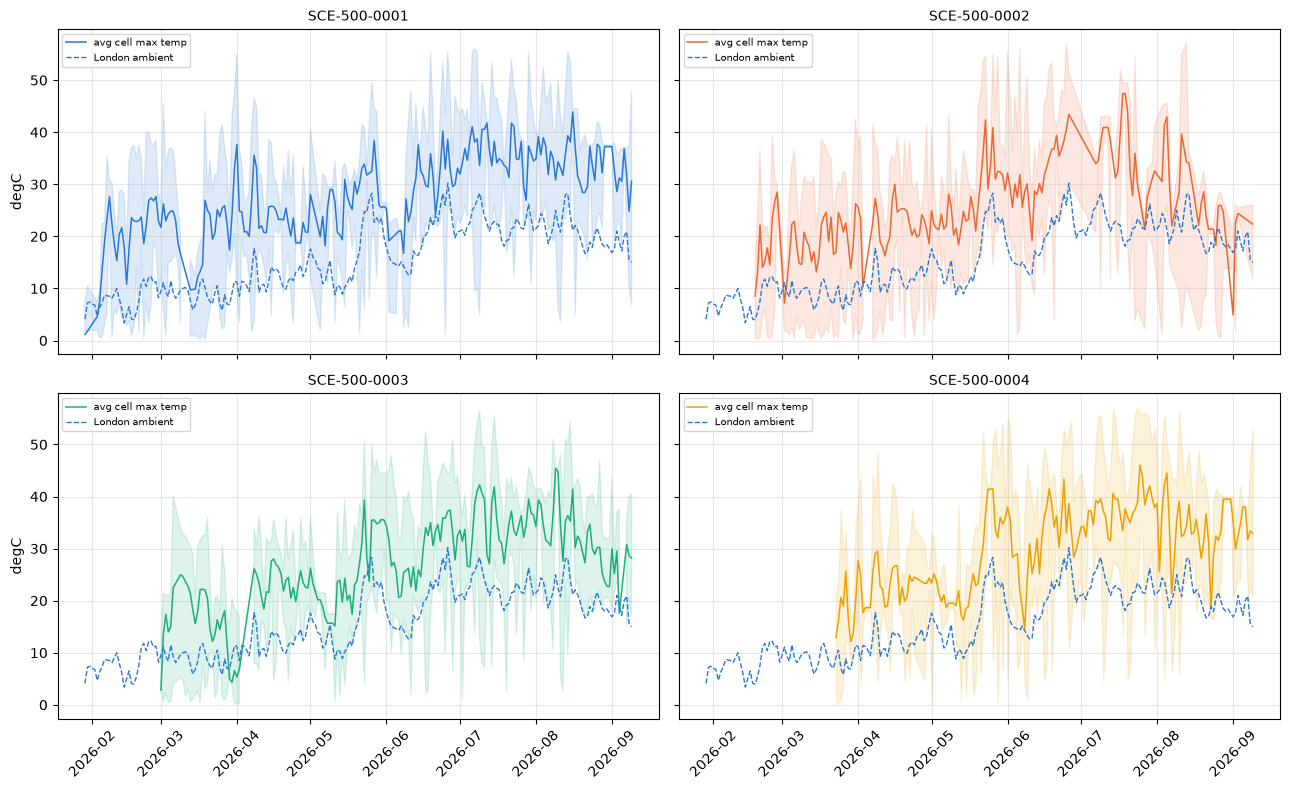

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, ep, color in zip(axes.flat, endpoints, palette):
    g = clean_temp[clean_temp["endpoint_id"] == ep]
    p1 = pack_1min[pack_1min["endpoint_id"] == ep]
    u_avg = g.groupby("day")["celltempmax_avg"].mean()
    u_max = g.groupby("day")["celltempmax_max"].max()
    u_min = p1.groupby(p1["ts_min"].dt.floor("D"))["celltempmax_avg"].min()
    u_min.index.name = "day"

    ax.fill_between(u_min.index, u_min.values, u_max.reindex(u_min.index).values, color=color, alpha=0.15)
    ax.plot(u_avg.index, u_avg.values, color=color, linewidth=1.1, label="avg cell max temp")
    ax.plot(weather["day"], weather["ambient_temp_mean_c"], color="#2a78d6", linewidth=1, linestyle="--", label="London ambient")
    ax.set_title(ep, fontsize=10)
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel("degC")
axes[1, 0].set_ylabel("degC")
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


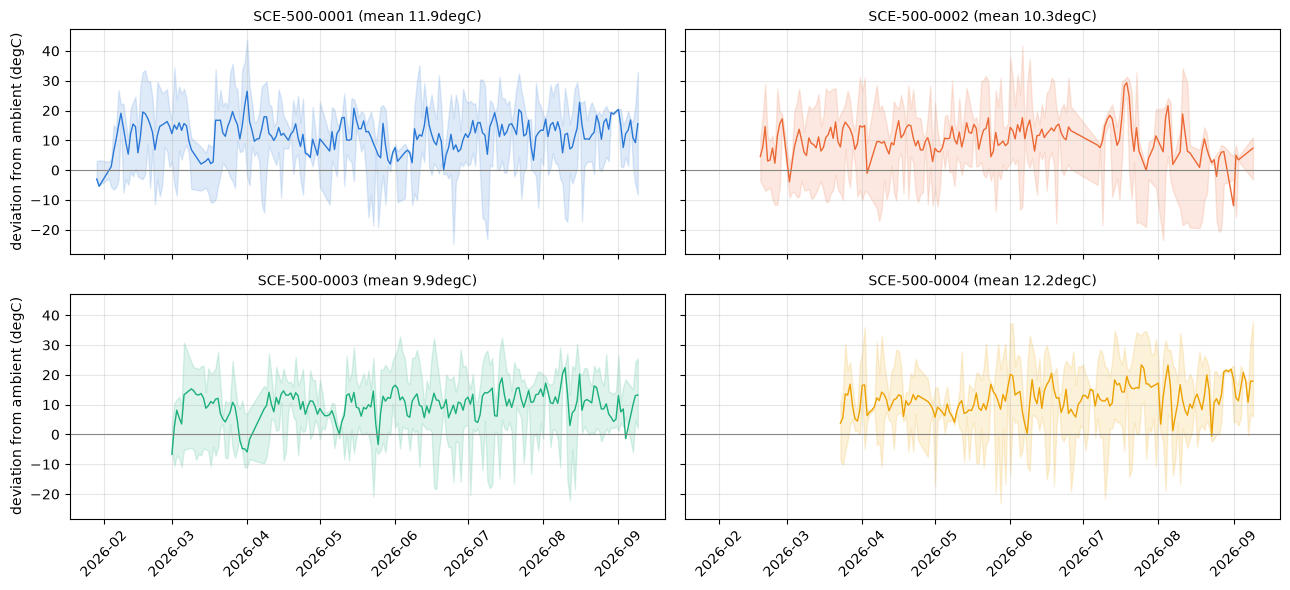

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True, sharey=True)
unit_dev = {}
for ax, ep, color in zip(axes.flat, endpoints, palette):
    g = clean_temp[clean_temp["endpoint_id"] == ep]
    p1 = pack_1min[pack_1min["endpoint_id"] == ep]
    u_avg = g.groupby("day")["celltempmax_avg"].mean()
    u_max = g.groupby("day")["celltempmax_max"].max()
    u_min = p1.groupby(p1["ts_min"].dt.floor("D"))["celltempmax_avg"].min()
    u_min.index.name = "day"

    dev = (u_avg - weather_by_day).dropna()
    dev_min = (u_min - weather_by_day).dropna()
    dev_max = (u_max - weather_by_day).dropna()
    unit_dev[ep] = dev

    ax.fill_between(dev.index, dev_min.reindex(dev.index).values, dev_max.reindex(dev.index).values,
                     color=color, alpha=0.15)
    ax.plot(dev.index, dev.values, color=color, linewidth=1)
    ax.axhline(0, color="#898781", linewidth=0.8)
    ax.set_title(f"{ep} (mean {dev.mean():.1f}degC)", fontsize=10)
axes[0, 0].set_ylabel("deviation from ambient (degC)")
axes[1, 0].set_ylabel("deviation from ambient (degC)")
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


Every unit sits in the same broad 9-13degC-above-ambient band - this isn't
one unit running hot and dragging up a fleet average, it's a consistent
fleet-wide relationship to ambient. SCE-500-0004 runs the highest mean
deviation (~12degC), consistent with it being the hottest-running unit
throughout this notebook; SCE-500-0002 the lowest (~10degC). A few units
(-0001, -0003, -0004) show a mild rise in their deviation from spring into
summer rather than holding perfectly flat, while -0002 stays essentially flat
across the whole deployment - a small difference, not a fault signal on its
own, but worth keeping in view alongside the capacity and pack-level findings
elsewhere in this notebook.


A clear seasonal signal, not a fleet-health one: average cell temperature
climbs from ~2degC in January to ~36degC in July, then eases through August
and into the first 9 days of September (~30degC) - tracking UK ambient
temperature across the deployment (29 Jan - 9 Sep), not usage intensity
(EFC/day above shows no comparable seasonal climb). Peak-ever
readings (56-57degC) and the count of days averaging over 45degC (0-16 per
unit, most on SCE-500-0002) are worth keeping in view operationally, but this
dataset carries no documented safety threshold to check them against, so no
pass/fail claim is made here.


In [37]:
by_pack_temp = clean_temp.groupby(["endpoint_id", "pack_number"])["celltempmax_avg"].mean().unstack()
by_pack_temp.round(1)


pack_number,1,2,3,4,5,6
endpoint_id,,,,,,
SCE-500-0001,27.8,27.4,28.0,28.1,27.7,27.6
SCE-500-0002,26.2,26.1,26.3,26.9,26.5,24.6
SCE-500-0003,26.3,26.7,26.8,27.6,27.2,27.1
SCE-500-0004,29.8,29.6,30.2,29.6,30.5,30.5


Packs run close to their siblings within each unit - no chronically hot pack
anywhere in the fleet. The one standout is SCE-500-0002 pack 6 (24.8degC vs
26.2-27.1degC for its siblings) - it runs *cooler*, not hotter, which is
consistent with the pack outage found earlier: an idle pack carries no
current and does no self-heating, so a lower average temperature is exactly
what that finding predicts, not a new concern.


### How often, not just how hot

The averages and monthly trend above answer "how hot does it get" - this
answers "how often", in real hours rather than a day-share proxy.
`pack_metrics_1min` now carries `celltempmax_avg`/`celltempmax_max` for the
whole deployment (added specifically for this), so exposure can be measured
directly instead of inferred from daily rollups.


In [38]:
# celltempmax_avg can freeze at its last reading for extended stretches (comms
# gaps that carry the last value forward rather than reporting nothing) - a run
# of the exact same reading for 24h+ is not a real, unmoving cell temperature,
# it's the sensor/pipeline stuck. Flag and exclude before measuring exposure.
TEMP_STUCK_MAX_MIN = 24 * 60

TEMP_COLS = ["endpoint_id", "pack_number", "ts_min", "celltempmax_avg", "temp_stuck"]
stuck_frames = []
for (ep, pn), g in pack_1min.groupby(["endpoint_id", "pack_number"]):
    g = g.sort_values("ts_min")
    same_as_prev = (g["celltempmax_avg"] == g["celltempmax_avg"].shift()) & g["celltempmax_avg"].notna()
    run_id = (~same_as_prev).cumsum()
    stuck = run_id.map(run_id.value_counts()) >= TEMP_STUCK_MAX_MIN
    stuck_frames.append(g[["endpoint_id", "pack_number", "ts_min", "celltempmax_avg"]].assign(temp_stuck=stuck))
pack_temp_1min = pd.concat(stuck_frames, ignore_index=True)  # slim: only the columns this section needs

print(f"Excluded as stuck (24h+ unchanged reading): {100*pack_temp_1min['temp_stuck'].mean():.1f}% of pack-minutes")
print(pack_temp_1min.groupby("endpoint_id")["temp_stuck"].mean().mul(100).round(1).rename("pct_excluded"))

clean_temp_1min = pack_temp_1min[~pack_temp_1min["temp_stuck"]].dropna(subset=["celltempmax_avg"]).copy()
del stuck_frames, pack_temp_1min  # precursor frames not needed once the cleaned slice exists
import gc
gc.collect()


Excluded as stuck (24h+ unchanged reading): 22.5% of pack-minutes
endpoint_id
SCE-500-0001    22.3
SCE-500-0002    22.9
SCE-500-0003    19.3
SCE-500-0004    25.9
Name: pct_excluded, dtype: float64


19654

20-26% of pack-minutes excluded per unit - a lot, and worth being direct
about why rather than quietly filtering it out. Breaking it down by pack
shows two things layered together: a broad ~15-25% baseline hitting every
pack roughly evenly (consistent with the same comms-blackout issue already
noted elsewhere in the fleet - see Data quality & dead ends - just showing up
here as a repeated last value instead of a missing row), plus a clear excess
on top of that baseline for the packs already known to have real outages:
SCE-500-0002 pack 6 (51% excluded vs 16-20% for its siblings) and
SCE-500-0003 pack 4 (33% vs 15-18% for its siblings) - both previously
confirmed above via current, not temperature. No new failure is being
uncovered here, just the same known issues showing up in a second signal.


In [39]:
THRESH_HOT, THRESH_VERY_HOT = 40.0, 45.0
rows = []
for ep, g in clean_temp_1min.groupby("endpoint_id"):
    rows.append({
        "endpoint_id": ep,
        "avg_hours_per_day_ge40": round(24 * (g["celltempmax_avg"] >= THRESH_HOT).mean(), 2),
        "avg_hours_per_day_ge45": round(24 * (g["celltempmax_avg"] >= THRESH_VERY_HOT).mean(), 2),
    })
pd.DataFrame(rows)


,endpoint_id,avg_hours_per_day_ge40,avg_hours_per_day_ge45
0,SCE-500-0001,2.63,0.79
1,SCE-500-0002,1.76,1.00
2,SCE-500-0003,2.10,0.70
3,SCE-500-0004,4.17,1.68


The real, hours-based numbers land close to what the earlier day-share proxy
implied, and confirm the same ranking: SCE-500-0004 spends roughly
**4.1 hours a day** above 40degC and 1.7h above 45degC - clearly the most of
the fleet - against 1.7-2.6h/day (>=40degC) for the other three units.


In [40]:
all_spells = []
for (ep, pn), g in clean_temp_1min.groupby(["endpoint_id", "pack_number"]):
    g = g.sort_values("ts_min").set_index("ts_min")
    hot = g["celltempmax_avg"] >= THRESH_HOT
    full_idx = pd.date_range(hot.index.min(), hot.index.max(), freq="1min")
    hot = hot.reindex(full_idx, fill_value=False)
    run_id = (hot != hot.shift()).cumsum()
    runs = pd.DataFrame({"hot": hot, "run": run_id}).groupby("run")["hot"].agg(["first", "size"])
    hot_runs = runs[runs["first"]]["size"]
    for n in hot_runs:
        all_spells.append({"endpoint_id": ep, "hours": n / 60.0})
all_spells = pd.DataFrame(all_spells)

spell_summary = all_spells.groupby("endpoint_id")["hours"].agg(
    n_spells="size", median_h="median", p90_h=lambda s: s.quantile(.9), max_h="max"
).round(2)
spell_summary


,n_spells,median_h,p90_h,max_h
endpoint_id,,,,
SCE-500-0001,454,3.19,12.20,40.08
SCE-500-0002,220,2.24,11.00,23.83
SCE-500-0003,358,3.27,11.70,23.07
SCE-500-0004,550,3.96,12.52,23.18


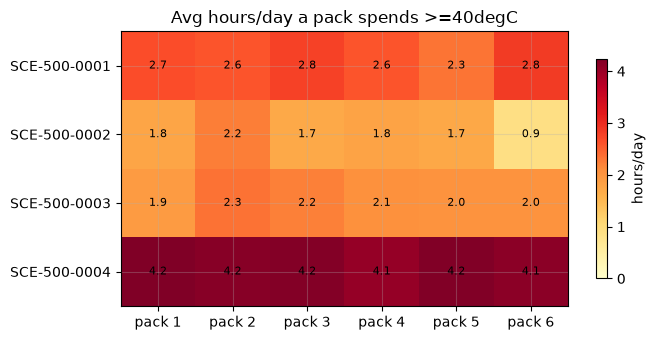

In [41]:
pack_hours_hot = (
    clean_temp_1min.assign(hot=clean_temp_1min["celltempmax_avg"] >= THRESH_HOT)
    .groupby(["endpoint_id", "pack_number"])["hot"].mean() * 24
).unstack()

fig, ax = plt.subplots(figsize=(7, 3.5))
im = ax.imshow(pack_hours_hot.values, aspect="auto", cmap="YlOrRd", vmin=0)
ax.set_yticks(range(len(pack_hours_hot.index)))
ax.set_yticklabels(pack_hours_hot.index)
ax.set_xticks(range(len(pack_hours_hot.columns)))
ax.set_xticklabels([f"pack {p}" for p in pack_hours_hot.columns])
ax.set_title("Avg hours/day a pack spends >=40degC")
for i in range(pack_hours_hot.shape[0]):
    for j in range(pack_hours_hot.shape[1]):
        ax.text(j, i, f"{pack_hours_hot.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="hours/day", shrink=0.8)
plt.tight_layout()
plt.show()


A hot spell, once it starts, typically runs 2-4 hours (median across units)
before dropping back below 40degC, with a right-skewed tail out to 12-40h for
the rare sustained event. SCE-500-0004 runs hot evenly across all 6 packs
(4.0-4.2h/day each) - a unit-level effect, not one pack dragging the rest up.
SCE-500-0002 pack 6 is again the outlier at the *cool* end (0.7h/day vs
1.7-2.0h/day for its siblings) - the idle pack story from earlier, not a new
one: no current, no self-heating, less time hot.


## Thermal health: limits, spread, rate of rise, peer comparison, drift

Five specific questions, in order: how close does the fleet run to the OEM's
actual limits (not a generic threshold); how much does temperature vary
*within* a pack and *across* packs in the same unit; how fast does a pack
heat up under load; how do packs compare to their peers under the *same*
load; and is any of this trending worse over time.

Two data limits apply throughout, same as noted above: the finest available
unit is the pack (6 per unit) - there's no module-level split within a pack
- and there's no ambient-temperature sensor anywhere in the fleet data, so
calendar month stands in as a rough ambient proxy where one is needed.
OEM limits used below (operating engineering's own figures, not a generic
battery threshold): **15-45degC normal operating range, 55degC before a pack
is pulled from service.**

Everything here builds on the same cleaning as the section above - stuck
(24h+ frozen) readings excluded - plus one more exclusion specific to
cross-pack comparisons: a pack already flagged unavailable (isolated, from
the capacity section right at the top of this notebook) is dropped too, since
comparing a genuinely disconnected pack's temperature against its active
siblings isn't a fair "peer" comparison.


In [42]:
clean_temp_avail = clean_temp_1min.merge(
    flags_1min[["endpoint_id", "pack_number", "ts_min", "unavailable"]],
    on=["endpoint_id", "pack_number", "ts_min"], how="left",
)
clean_temp_avail["unavailable"] = clean_temp_avail["unavailable"].fillna(False).astype(bool)
clean_temp_avail = clean_temp_avail[~clean_temp_avail["unavailable"]]
print(f"{len(clean_temp_avail):,} pack-minutes available for peer/spread/drift comparisons "
      f"(of {len(clean_temp_1min):,} after the stuck-value filter alone)")


4,347,449 pack-minutes available for peer/spread/drift comparisons (of 4,393,817 after the stuck-value filter alone)


### At a glance

The four headline numbers from everything below, before the detail.


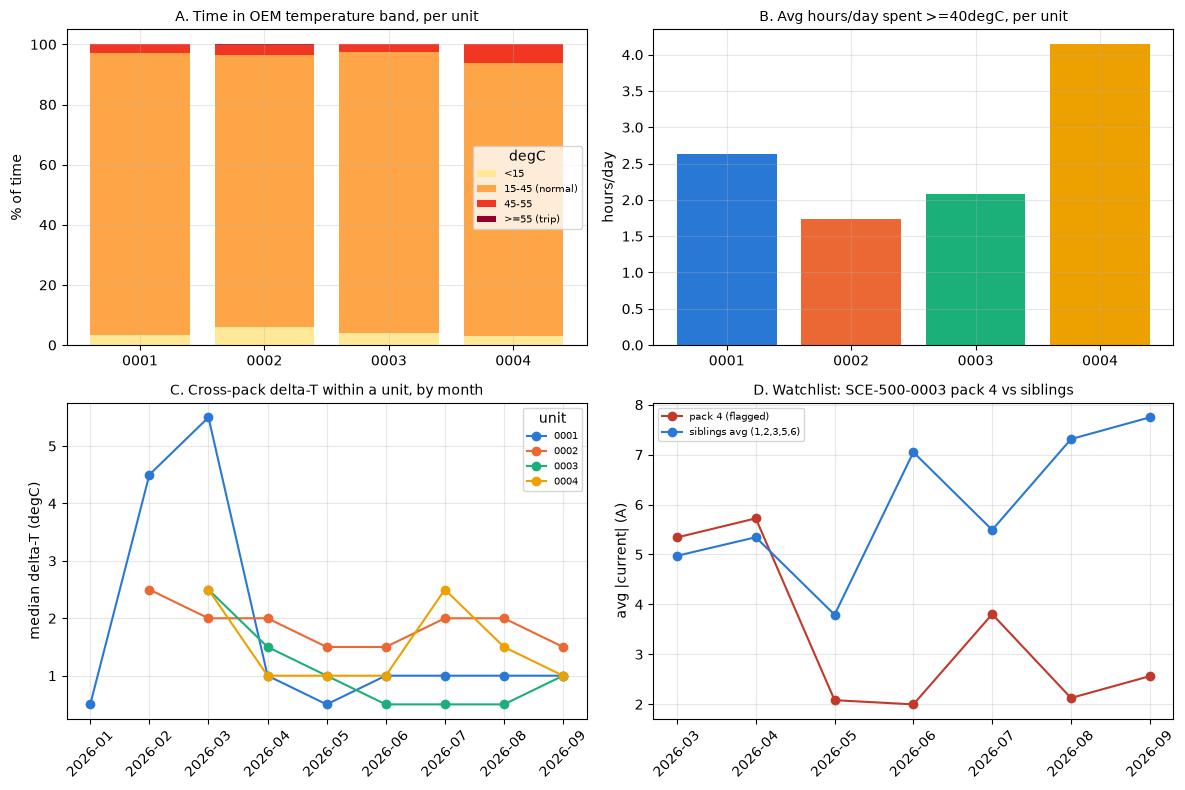

In [43]:
OEM_MIN, OEM_MAX, OEM_TRIP = 15.0, 45.0, 55.0

# panel A data: OEM band time-share per unit
band_rows = []
for ep, g in clean_temp_avail.groupby("endpoint_id"):
    t = g["celltempmax_avg"]
    band_rows.append({
        "endpoint_id": ep,
        "<15": 100 * (t < OEM_MIN).mean(),
        "15-45 (normal)": 100 * ((t >= OEM_MIN) & (t <= OEM_MAX)).mean(),
        "45-55": 100 * ((t > OEM_MAX) & (t < OEM_TRIP)).mean(),
        ">=55 (trip)": 100 * (t >= OEM_TRIP).mean(),
    })
band_headline = pd.DataFrame(band_rows).set_index("endpoint_id")

# panel B data: hours/day >=40degC per unit
hours_hot_headline = clean_temp_avail.groupby("endpoint_id")["celltempmax_avg"].apply(lambda s: 24 * (s >= 40).mean())

# panel C data: cross-pack delta-T within a unit, by month (built once here, reused in section 2 below)
piv_cross_pack = clean_temp_avail.pivot_table(index=["endpoint_id", "ts_min"], columns="pack_number", values="celltempmax_avg")
n_avail = piv_cross_pack.notna().sum(axis=1)
cross_pack_dt = (piv_cross_pack.max(axis=1) - piv_cross_pack.min(axis=1))[n_avail >= 4].reset_index(name="delta_t")
cross_pack_dt["month"] = cross_pack_dt["ts_min"].dt.to_period("M")
monthly_dt = cross_pack_dt.groupby(["endpoint_id", "month"])["delta_t"].median().unstack("endpoint_id")

# panel D data: the one flagged pack (SCE-500-0003 pack 4) vs its 5 siblings' average
sce3 = pack_1min[pack_1min["endpoint_id"] == "SCE-500-0003"]
sce3_month = sce3["ts_min"].dt.to_period("M")
pack4_current = sce3.loc[sce3["pack_number"] == 4].groupby(sce3_month)["current_avg"].apply(lambda s: s.abs().mean())
sibling_current = sce3.loc[sce3["pack_number"] != 4].groupby(sce3_month)["current_avg"].apply(lambda s: s.abs().mean())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

ax = axes[0, 0]
bottom = np.zeros(len(band_headline))
for label, color in zip(band_headline.columns, plt.cm.YlOrRd(np.linspace(0.15, 0.95, 4))):
    ax.bar([e.replace("SCE-500-", "") for e in band_headline.index], band_headline[label], bottom=bottom, label=label, color=color)
    bottom += band_headline[label].to_numpy()
ax.set_title("A. Time in OEM temperature band, per unit", fontsize=10)
ax.set_ylabel("% of time")
ax.legend(fontsize=7, title="degC")

ax = axes[0, 1]
ax.bar([e.replace("SCE-500-", "") for e in hours_hot_headline.index], hours_hot_headline.values, color=palette)
ax.set_title("B. Avg hours/day spent >=40degC, per unit", fontsize=10)
ax.set_ylabel("hours/day")

ax = axes[1, 0]
for ep, color in zip(endpoints, palette):
    ax.plot([str(m) for m in monthly_dt.index], monthly_dt[ep], marker="o", label=ep.replace("SCE-500-", ""), color=color)
ax.set_title("C. Cross-pack delta-T within a unit, by month", fontsize=10)
ax.set_ylabel("median delta-T (degC)")
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=7, title="unit")

ax = axes[1, 1]
ax.plot([str(m) for m in pack4_current.index], pack4_current.values, marker="o", color="#c0392b", label="pack 4 (flagged)")
ax.plot([str(m) for m in sibling_current.index], sibling_current.values, marker="o", color="#2a78d6", label="siblings avg (1,2,3,5,6)")
ax.set_title("D. Watchlist: SCE-500-0003 pack 4 vs siblings", fontsize=10)
ax.set_ylabel("avg |current| (A)")
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


**A.** Fleet spends 90-94% of its time inside the OEM's normal 15-45degC
band; the trip threshold (55degC) is essentially never sustained.
**B.** SCE-500-0004 is the clear outlier for time spent hot - confirms the
finding from the Temperature section above, now checked against the OEM
band specifically. **C.** Cross-pack spread is small and flat across
months - no fleet-wide cooling-imbalance trend developing. **D.** The one
real exception to all of the above: SCE-500-0003 pack 4's current draw has
fallen away from its siblings since May and the gap keeps widening - this is
the one finding here that needs following up, not the averages.


### 1. Absolute temperature vs OEM limits

Share of time spent below the operating minimum, within the normal band,
above it but short of the trip point, and at/above the trip point - using
only minutes a pack was actually available (per above), since the OEM range
describes operating conditions, not a disconnected pack sitting cold.


In [44]:
OEM_MIN, OEM_MAX, OEM_TRIP = 15.0, 45.0, 55.0

rows = []
for ep, g in clean_temp_avail.groupby("endpoint_id"):
    t = g["celltempmax_avg"]
    rows.append({
        "endpoint_id": ep,
        "pct_below_15": round(100 * (t < OEM_MIN).mean(), 1),
        "pct_normal_15_45": round(100 * ((t >= OEM_MIN) & (t <= OEM_MAX)).mean(), 1),
        "pct_45_to_55": round(100 * ((t > OEM_MAX) & (t < OEM_TRIP)).mean(), 1),
        "pct_ge_55_trip": round(100 * (t >= OEM_TRIP).mean(), 2),
    })
pd.DataFrame(rows)


,endpoint_id,pct_below_15,pct_normal_15_45,pct_45_to_55,pct_ge_55_trip
0,SCE-500-0001,3.3,93.8,2.9,0.03
1,SCE-500-0002,6.0,90.5,3.5,0.06
2,SCE-500-0003,4.2,93.2,2.6,0.02
3,SCE-500-0004,2.9,90.8,6.3,0.02


In [45]:
trip_events = clean_temp_avail[clean_temp_avail["celltempmax_avg"] >= OEM_TRIP]
trip_days = trip_events.assign(day=trip_events["ts_min"].dt.floor("D")).groupby(
    ["endpoint_id", "pack_number", "day"]
).size()
print(f"Minutes at/above {OEM_TRIP:.0f}degC: {len(trip_events)} (of {len(clean_temp_avail):,})")
print(f"Distinct pack-days touching {OEM_TRIP:.0f}degC+: {trip_days.reset_index()['day'].nunique()}")
print(trip_days.reset_index().groupby("endpoint_id").size().rename("pack_days_at_trip"))


Minutes at/above 55degC: 1384 (of 4,347,449)
Distinct pack-days touching 55degC+: 22
endpoint_id
SCE-500-0001    29
SCE-500-0002    17
SCE-500-0003     5
SCE-500-0004    14
Name: pack_days_at_trip, dtype: int64


The fleet spends the overwhelming majority of its time inside the OEM's
normal 15-45degC band (90-94%). Above 45degC is a real but small share
(2.6-6.3%, highest on SCE-500-0004, consistent with it being the
hottest-running unit throughout this notebook). The trip threshold (55degC)
is touched only in isolated instances - a handful of pack-days, never a
sustained condition - so this doesn't look like a fleet regularly running
into the OEM's actual upper limit. The overlooked side is the *cold* end:
2.9-6.0% of time below 15degC (highest on SCE-500-0002), concentrated in the
winter months per the seasonal trend above - worth a look if the OEM's
minimum matters for charge acceptance or warranty terms, since this dataset
alone can't say whether the BMS derates charging in that range.


### 2. Temperature spread (delta-T)

Two angles: spread *within* a pack (its own hottest cell vs its own coolest
cell, daily) and spread *across* packs in the same unit at the same moment
(the practical stand-in for a module/rack comparison here, since there's no
module-level data).


In [46]:
within_pack = pack[(pack["celltempmax_avg"] > 0) & (pack["celltempmin_avg"] > 0)].copy()
within_pack["delta_t"] = within_pack["celltempmax_avg"] - within_pack["celltempmin_avg"]
within_pack.groupby("endpoint_id")["delta_t"].agg(
    median="median", p90=lambda s: s.quantile(.9), max="max"
).round(2)


,median,p90,max
endpoint_id,,,
SCE-500-0001,0.81,2.62,5.89
SCE-500-0002,1.20,2.50,4.89
SCE-500-0003,1.00,1.78,5.50
SCE-500-0004,1.00,2.45,8.64


In [47]:
# cross_pack_dt / monthly_dt already computed for panel C of the "At a glance" dashboard above - reused here
cross_pack_dt.groupby("endpoint_id")["delta_t"].agg(
    median="median", p90=lambda s: s.quantile(.9), max="max"
).round(2)


,median,p90,max
endpoint_id,,,
SCE-500-0001,1.0,6.39,22.600000
SCE-500-0002,2.0,3.50,35.299999
SCE-500-0003,1.0,3.10,21.830000
SCE-500-0004,1.0,4.00,24.250000


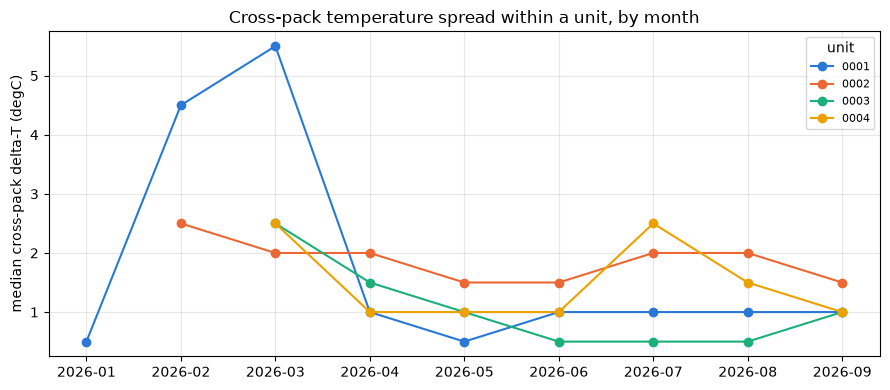

In [48]:
fig, ax = plt.subplots(figsize=(9, 4))
for ep, color in zip(endpoints, palette):
    ax.plot([str(m) for m in monthly_dt.index], monthly_dt[ep], marker="o", label=ep.replace("SCE-500-", ""), color=color)
ax.set_ylabel("median cross-pack delta-T (degC)")
ax.set_title("Cross-pack temperature spread within a unit, by month")
ax.legend(title="unit", fontsize=8)
plt.tight_layout()
plt.show()


Within a pack, cells stay tight (median ~1degC, p90 under ~2.5degC across all
four units) - no sign of internal cell imbalance. Across packs within a unit,
the median spread is also small (0.5-2degC) and, critically, **not growing
month over month** - after the noisier early rollout months it settles into
a stable band through to September, the same "no fade" conclusion as the
capacity-trend finding earlier, now checked from a completely different
angle (temperature instead of capacity) and agreeing with it.


### 3. Rate of temperature rise (dT/dt)

During discharge, all 6 packs in a unit experience the same shared power
event at the same time - a natural apples-to-apples comparison. For each
discharge session (>=30 min, same detection as the Charge time section but
applied to `ac_out_pwr`), each pack's own heating rate over that session
(degC/hour, first/last 10 minutes averaged to reduce noise) is compared
against its 5 siblings under that identical event.


In [49]:
MIN_SESSION_MIN = 30
dtdt_rows = []
for ep in endpoints:
    g_u = u[u["endpoint_id"] == ep].sort_values("ts_min")
    sess = detect_power_sessions(g_u, "ac_out_pwr")
    sess = sess[sess["duration_h"] * 60 >= MIN_SESSION_MIN]

    pack_temp = pack_1min[pack_1min["endpoint_id"] == ep].pivot_table(
        index="ts_min", columns="pack_number", values="celltempmax_avg"
    )
    for _, row in sess.iterrows():
        start_win = pack_temp.loc[row["start"]: row["start"] + pd.Timedelta(minutes=10)].mean()
        end_win = pack_temp.loc[row["end"] - pd.Timedelta(minutes=10): row["end"]].mean()
        rate = (end_win - start_win) / row["duration_h"]
        for pn, r in rate.items():
            if pd.notna(r):
                dtdt_rows.append({"endpoint_id": ep, "pack_number": pn, "rate_c_per_h": r})

dtdt = pd.DataFrame(dtdt_rows)
dtdt.groupby(["endpoint_id", "pack_number"])["rate_c_per_h"].median().unstack().round(2)


pack_number,1,2,3,4,5,6
endpoint_id,,,,,,
SCE-500-0001,2.84,2.63,2.67,2.68,2.72,2.32
SCE-500-0002,3.57,3.76,3.81,3.52,3.73,0.00
SCE-500-0003,2.44,2.84,2.64,1.28,2.35,2.48
SCE-500-0004,2.66,2.60,2.61,2.87,2.80,2.64


Most packs across the fleet heat up at a fairly consistent 2.3-3.8degC/hour
during discharge. Two packs break that pattern, and they're both already
known from earlier sections - but for different reasons:

- **SCE-500-0002 pack 6**: ~0degC/hour, because it's the chronically isolated
  pack from the capacity section - no current, no self-heating. Expected,
  not new.
- **SCE-500-0003 pack 4**: ~1.3degC/hour vs 2.4-2.8degC/hour for its 5
  siblings under the *same* discharge events - measurably slower than every
  other contributing pack in the fleet. Unlike pack 6, this pack is not
  flagged unavailable (it isn't near-zero current) - this is a genuinely new
  signal, followed up below.


### 4. Peer comparison at matched conditions

Pack 4 on SCE-500-0003 heating slower than its siblings under the same load
could just mean it's carrying less current - checking that directly.


In [50]:
sce3 = pack_1min[pack_1min["endpoint_id"] == "SCE-500-0003"].copy()
sce3["month"] = sce3["ts_min"].dt.to_period("M")
monthly_current = sce3.groupby(["month", "pack_number"])["current_avg"].apply(lambda s: s.abs().mean()).unstack("pack_number")
monthly_current.round(2)


pack_number,1,2,3,4,5,6
month,,,,,,
2026-03,4.57,4.67,5.17,5.34,5.29,5.16
2026-04,5.24,5.40,5.41,5.72,5.68,4.99
2026-05,4.26,3.94,3.84,2.08,3.48,3.44
2026-06,7.11,7.15,6.74,2.00,7.17,7.07
2026-07,5.79,4.97,4.67,3.80,6.06,5.97
2026-08,7.38,7.55,7.16,2.13,7.24,7.24
2026-09,7.77,7.95,7.58,2.56,7.74,7.71


Confirmed, and it's worse than the brief "packs 3/4 dip" already noted under
Data quality & dead ends. Pack 3 recovered after that early-year event and
has tracked its siblings closely ever since. **Pack 4 has not** - from May
2026 onward its current draw sits at 2-3.8A while all 5 siblings climb
together to 7-8A by September, a gap that *widens* over time rather than
holding steady. This is a separate, ongoing issue, not a resolved one, and
it wasn't caught by either of the fleet's existing pack-health checks: its
BMS-reported capacity still reads a normal ~70-75 kWh (same "BMS looks fine
even when a pack isn't contributing" pattern as pack 6), and its current,
while low, isn't near-zero enough to trip the `unavailable` flag used
earlier for capacity correction.


### 5. Long-term drift

Each pack's average temperature, expressed as a deviation from its own
unit's mean for that month - this cancels out the shared seasonal/ambient
signal (all 6 packs in a unit see the same ambient), so a pack-specific issue
that's genuinely getting worse should show up as a growing deviation, not
just the whole unit getting warmer with summer.


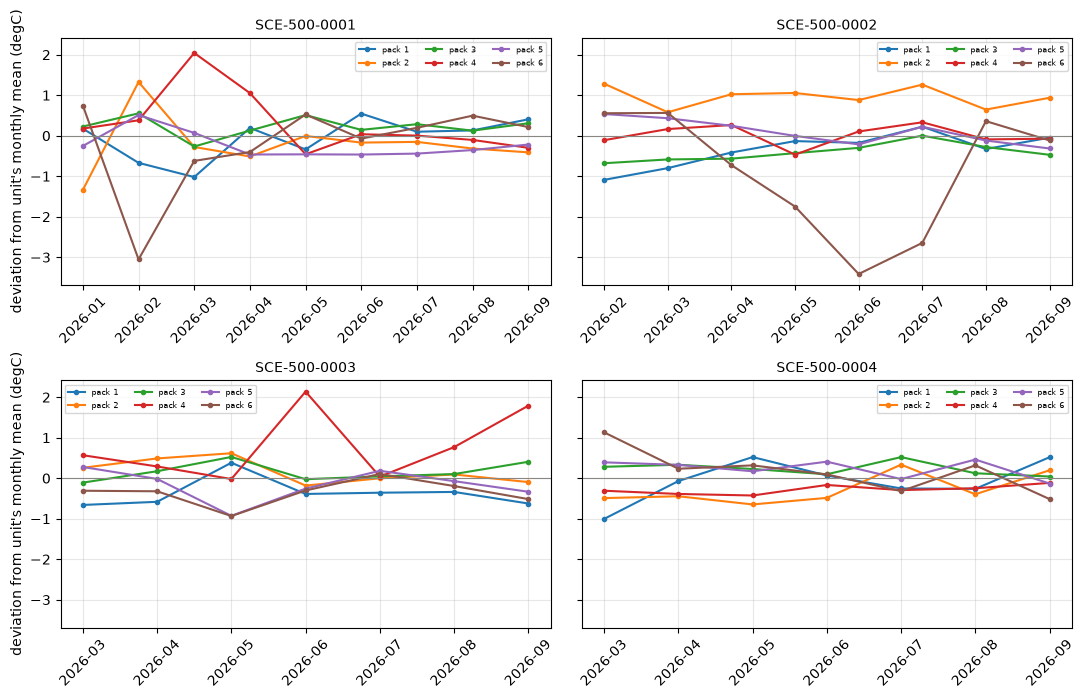

In [51]:
clean_temp_avail["month"] = clean_temp_avail["ts_min"].dt.to_period("M")
unit_month_mean = clean_temp_avail.groupby(["endpoint_id", "month"])["celltempmax_avg"].transform("mean")
clean_temp_avail["dev_from_unit_mean"] = clean_temp_avail["celltempmax_avg"] - unit_month_mean

drift = clean_temp_avail.groupby(["endpoint_id", "pack_number", "month"])["dev_from_unit_mean"].mean().unstack("month")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, ep in zip(axes.flat, endpoints):
    for pn in range(1, 7):
        if pn in drift.loc[ep].index:
            ax.plot([str(m) for m in drift.columns], drift.loc[(ep, pn)], marker=".", label=f"pack {pn}")
    ax.axhline(0, color="#898781", linewidth=0.8)
    ax.set_title(ep, fontsize=10)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=6, ncol=3)
axes[0, 0].set_ylabel("deviation from unit's monthly mean (degC)")
axes[1, 0].set_ylabel("deviation from unit's monthly mean (degC)")
plt.tight_layout()
plt.show()


Almost every pack sits close to zero deviation, month after month, with no
trend - exactly what "no drift" should look like once the shared seasonal
signal is removed. SCE-500-0002 pack 6 sits persistently negative (cooler
than its siblings, the idle-pack story again). **SCE-500-0003 pack 4 is the
one pack trending the wrong way**: from roughly +0.6degC above its unit's
mean in March to +1.8degC by September - running steadily *warmer* than its
siblings' average, in the same months its current draw is falling further
behind them.

Put together, pack 4 is drawing less current than its siblings *and* running
relatively hotter, and the gap on both measures is widening rather than
holding steady - a combination consistent with rising internal resistance
(more heat per amp actually delivered, less current the BMS is willing to
push through it), though this dataset can't confirm root cause. Worth a
physical inspection call-out rather than filing this under the existing
"brief dip, no sustained underperformance" note - that note describes what
happened in March/April and pack 3's recovery correctly, but no longer
describes pack 4.


## Data quality & dead ends

Worth keeping in view before repeating any of this analysis:

- **`avg_load` is corrupted at source** - sporadic outliers in the millions (a
  telemetry glitch), excluded throughout. `peak_load` and `ac_out_pwr` are clean.
- **`soc_avg`, `total_kwh_in`, `total_kwh_out` have zero-dropout glitches** -
  brief telemetry read failures defaulting to exactly 0.0, in runs of a few
  minutes. Masked and forward-filled; without this, cycle counts run ~10% high
  (a momentary zero-dropout mid-cycle spuriously re-arms the recharge trigger).
- **Comms blackouts**: 9-29% of minutes per unit have no telemetry at all.
  Real down/shutdown time is negligible (<0.05%) - this is a visibility gap, not
  a reliability claim.
- **`celltempmin_min` defaults to exactly 0.0degC on 44% of pack-days**, spread
  evenly across every month including July/August - a telemetry floor, not
  real ambient cold. `celltempmax_avg`/`celltempmax_max` have the same
  zero-default glitch far less often (1.6% of pack-days) and are used for the
  Temperature section instead.
- **`celltempmax_avg` at 1-min resolution freezes at its last reading for
  extended stretches** - 20-26% of pack-minutes per unit sit in a run of the
  exact same value lasting 24h or more, excluded before the hours-based
  temperature exposure numbers above. Mostly a broad, even-across-every-pack
  baseline (same comms-blackout issue as above, just carrying the last value
  forward here instead of leaving a gap), plus a clear excess specifically on
  the packs with already-confirmed real outages (SCE-500-0002 pack 6,
  SCE-500-0003 pack 4) - not a new fault, the same ones showing up twice.
- **`dc_charger`/EV-charger interface shows no real usage** in 90 days of live
  data - never reaches a "Charging" state, `ChargerAvailability` never reports
  "Operative". Not a reliable signal for vehicle-charging-session analysis.
- **Confirmed real pack outages** (not a telemetry artifact - voltage/current/SoC
  genuinely drop to ~0 or freeze flat for days at a time): SCE-500-0002 pack 6
  flickered on and off through Feb-mid April, then went continuously idle for
  ~90 days straight (18 Apr onward - see "At 1-min resolution" below), while
  SCE-500-0001 pack 4 had a single ~10-day outage in late May. SCE-500-0003 packs
  3 and 4 both dip on the exact same handful of dates (early March, late
  March/early April) - more likely one shared event (or the same telemetry
  glitch as above) than two independent pack failures. Pack 3 recovered from
  that event; **pack 4 did not** - Thermal health (below) finds it drawing
  steadily less current than its siblings from May onward, a gap that widens
  rather than closes, alongside a rising relative temperature - an ongoing,
  separate, worsening issue, not the same brief one as pack 3's. All four have the
  largest share of near-zero nominal-energy readings of any packs in the fleet,
  consistent with this being real hardware, not noise. Effect on the headline
  capacity figures is small (0.6-4.8%, biggest for -0002) - excluded via the
  same >20 kWh floor used for capacity above.
- **Two framings we tried and dropped**:
  - *Overload/power headroom*: even at the fleet's single highest simultaneous
    draw ever recorded, combined output was only 37% of combined rated capacity.
    Power headroom is not the constraint.
  - *"No fresh reserve" during the evening vehicle-return window*: descriptively
    true (no unit >=85% charged 51% of days in that window), but checking
    whether energy delivered was actually constrained on those days showed the
    opposite - the tightest days delivered *more* energy, including the fleet's
    single highest day, not less. This looks like normal response to higher
    demand, not evidence of turned-away demand. No vehicle-level session data
    exists to confirm unmet demand directly either way.


In [52]:
pct_overlap = pct_post  # post-rollout figure - the steady-state rate, not diluted by the ramp-up months
display(Markdown(f'''\
## Summary

- Fleet delivered **{total_throughput:,.0f} kWh** across **{total_active_days} unit-active-days**
  ({total_throughput/total_active_days:.0f} kWh/unit/active-day on average).
- Each unit does **{avg_efc.min():.2f}-{avg_efc.max():.2f} equivalent full cycles/day** when in use.
- **Each unit added was needed**: throughput per live unit didn't decline as the
  fleet grew from 1 to 4 - no dilution, each addition found genuine new demand.
- **{pct_overlap:.0f}% of active days** run 3+ units together, once all 4 were deployed -
  a fleet worked as a group, not a rollout artifact.
- Clear **weekday-only** usage pattern.
- No capacity fade over ~7 months.
- Power headroom is ample; the constraint (to the extent this data shows one) is
  energy/duty-cycle, not instantaneous power.
- **Open question**: total fleet throughput has been flat since all 4 went live -
  this data shows the units were needed, but doesn't itself prove unmet demand for
  a 5th. That needs either a period the current fleet visibly can't keep up with,
  or direct evidence (declined jobs, turned-away vehicles) not present here.
'''))


## Summary

- Fleet delivered **97,990 kWh** across **508 unit-active-days**
  (193 kWh/unit/active-day on average).
- Each unit does **0.61-0.70 equivalent full cycles/day** when in use.
- **Each unit added was needed**: throughput per live unit didn't decline as the
  fleet grew from 1 to 4 - no dilution, each addition found genuine new demand.
- **69% of active days** run 3+ units together, once all 4 were deployed -
  a fleet worked as a group, not a rollout artifact.
- Clear **weekday-only** usage pattern.
- No capacity fade over ~7 months.
- Power headroom is ample; the constraint (to the extent this data shows one) is
  energy/duty-cycle, not instantaneous power.
- **Open question**: total fleet throughput has been flat since all 4 went live -
  this data shows the units were needed, but doesn't itself prove unmet demand for
  a 5th. That needs either a period the current fleet visibly can't keep up with,
  or direct evidence (declined jobs, turned-away vehicles) not present here.
